# EEG Mental Arithmetic: Rest vs Task Classification
End-to-end pipeline: preprocessing (filter, ICA, AutoReject) -> feature extraction -> EDA -> leave-one-subject-out (LOSO) evaluation -> clean hold-out test -> robustness checks.

**How to read the results.** Every number reported by the modelling sections comes from pipelines in which imputation, scaling and feature selection are fitted on training subjects only. Section 16 re-runs the headline model without the channels and bands most vulnerable to eye/muscle artifacts, so you can see how much of the accuracy is neural. Known limitations are listed in the last section.

## 1. Install dependencies

In [4]:
# Installs pinned versions. If pip changes numpy/scipy, the already-imported compiled
# extensions no longer match the files on disk, so the kernel is restarted once.
# After the restart, simply run all cells again.
import subprocess, sys, os

def _installed_version(pkg):
    try:
        import importlib.metadata as m
        return m.version(pkg)
    except Exception:
        return None

_before = {p: _installed_version(p) for p in ("numpy", "scipy")}

_pip_cmd = [
    sys.executable, "-m", "pip", "install", "-q",
    "mne==1.12.1", "matplotlib==3.10.0", "pandas==2.3.3", "seaborn==0.13.2",
    "antropy==0.2.2", "pywavelets==1.9.0", "autoreject==0.5.0",
    "scikit-learn==1.6.1", "joblib==1.5.3", "xgboost==3.2.0", "shap==0.51.0",
    "numba==0.67.0", "llvmlite==0.49.0", "tqdm==4.70.1",
]
result = subprocess.run(_pip_cmd, capture_output=True, text=True)
print(result.stdout[-1500:])
if result.returncode != 0:
    print(result.stderr[-3000:])
    raise RuntimeError("pip install failed -- see output above")

_after = {p: _installed_version(p) for p in ("numpy", "scipy")}
if any(_before[p] and _before[p] != _after[p] for p in _before):
    print(f"numpy/scipy changed ({_before} -> {_after}). Restarting the kernel; re-run all cells afterwards.")
    os.kill(os.getpid(), 9)
else:
    print(f"numpy {_after['numpy']} and scipy {_after['scipy']} unchanged -- no restart needed.")


numpy 2.1.3 and scipy 1.16.3 unchanged -- no restart needed.


## 2. Version check

In [5]:
import numpy as np, numba, llvmlite, antropy as ant, mne, sklearn, xgboost, shap
print("NumPy:", np.__version__, "| Numba:", numba.__version__, "| llvmlite:", llvmlite.__version__)
print("AntroPy:", ant.__version__, "| MNE:", mne.__version__, "| scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__, "| SHAP:", shap.__version__)

NumPy: 2.1.3 | Numba: 0.67.0 | llvmlite: 0.49.0
AntroPy: 0.2.2 | MNE: 1.12.1 | scikit-learn: 1.6.1
XGBoost: 3.2.0 | SHAP: 0.51.0


## 3. Imports

In [6]:
import os, re, time, json, hashlib, warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
from scipy import signal, stats
import mne
import matplotlib.pyplot as plt
import seaborn as sns
import antropy as ant
import pywt
import shap
import joblib
from autoreject import AutoReject
from joblib import Parallel, delayed
from tqdm.auto import tqdm

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, VotingClassifier)
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, roc_curve, auc, f1_score,
                             matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from xgboost import XGBClassifier

# Hide only noisy deprecation chatter; real warnings stay visible.
warnings.filterwarnings('ignore', category=FutureWarning)
mne.set_log_level('ERROR')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 11})

## 4. Constants

In [7]:
SEED = 42
# QUICK=1 (set the EEG_QUICK environment variable) gives a fast smoke-test run.
QUICK = os.environ.get('EEG_QUICK', '0') == '1'
RUN_TUNING = not QUICK        # grouped-CV hyperparameter search for the model zoo
TUNE_ITERS = 2 if QUICK else 12
TOP_K = 150                   # in-fold ANOVA feature selection (fitted on training subjects only)

BAND_DEFS = {
    'delta': (0.5, 4), 'theta': (4, 8), 'alpha': (8, 13),
    'beta': (13, 30), 'gamma': (30, 45),
}

STANDARD_CHANNELS = ['Fp1', 'Fp2', 'F3', 'F4', 'Fz', 'F7', 'F8',
                     'C3', 'C4', 'Cz', 'T3', 'T4', 'T5', 'T6',
                     'P3', 'P4', 'Pz', 'O1', 'O2']

REGIONS = {
    'Frontal':   ['Fp1', 'Fp2', 'F3', 'F4', 'Fz', 'F7', 'F8'],
    'Central':   ['C3', 'C4', 'Cz'],
    'Temporal':  ['T3', 'T4', 'T5', 'T6'],
    'Parietal':  ['P3', 'P4', 'Pz'],
    'Occipital': ['O1', 'O2'],
}

# Frontal-pole and temporal sites pick up eye movements and jaw/scalp muscle activity most strongly.
ARTIFACT_PRONE_CHANNELS = ['Fp1', 'Fp2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6']

CONNECTIVITY_PAIRS = [('Fp1', 'Fp2'), ('F3', 'F4'), ('Fz', 'Pz'), ('F7', 'F8')]

PREPROCESSING_CONFIG = {
    'l_freq': 1.0,
    'h_freq': 45.0,          # matches the gamma band edge (30-45 Hz) and the recording's own 45 Hz low-pass
    'notch_freq': 50.0,      # the 45 Hz FIR transition band does not fully remove mains noise
    'sfreq': 128,
    'epoch_length': 4.0,
    'epoch_overlap': 0.0,
    'montage': 'standard_1020',
    'use_ica': True,         # remove ocular / muscle components before epoching
    'ica_n_components': 15,  # < 18 = rank after average reference of 19 channels
    'ica_max_exclude': 4,
}
FEATURE_VERSION = 'v3'       # bump when feature definitions change (invalidates the cache)

# Fixed hold-out test subjects (numeric ids -> Subject01, Subject22, Subject35).
HOLDOUT_SUBJECT_IDS = [1, 22, 35]


def config_hash(config=PREPROCESSING_CONFIG):
    """Short fingerprint of everything that changes the cached features."""
    payload = json.dumps({'cfg': config, 'bands': BAND_DEFS, 'ver': FEATURE_VERSION}, sort_keys=True)
    return hashlib.md5(payload.encode()).hexdigest()[:8]

## 5. Locate dataset

In [8]:
def find_dataset():
    """Return the folder containing Subject00_1.edf. Set EEG_DATA_PATH to override."""
    candidates = []
    if os.environ.get('EEG_DATA_PATH'):
        candidates.append(os.environ['EEG_DATA_PATH'])
    if os.path.exists('/kaggle/input'):
        for root, _, files in os.walk('/kaggle/input'):
            if 'Subject00_1.edf' in files:
                candidates.append(root)
                break
    candidates += [os.getcwd(), os.path.join(os.getcwd(), 'eeg-during-mental-arithmetic-tasks-1.0.0')]
    for c in candidates:
        if os.path.exists(os.path.join(c, 'Subject00_1.edf')):
            return c
    raise FileNotFoundError(
        'Dataset not found. Put the EDF files next to this notebook or set the EEG_DATA_PATH '
        'environment variable to the folder that contains Subject00_1.edf.')

data_path = find_dataset()
output_dir = (os.environ.get('EEG_OUTPUT_DIR')
              or ('/content' if os.path.exists('/content')
                  else '/kaggle/working' if os.path.exists('/kaggle/working') else os.getcwd()))
os.makedirs(output_dir, exist_ok=True)
print(f'Data path:   {data_path}\nOutput path: {output_dir}')

Data path:   /kaggle/input/datasets/poornasrinandyala/eeg-during-mental-arithmetic-tasks-1-0-0/eeg-during-mental-arithmetic-tasks-1.0.0
Output path: /content


## 6. Preprocessing
Per subject: load -> keep only channels that match the 10-20 montage -> average reference -> 1-45 Hz FIR band-pass + 50 Hz notch -> resample to 128 Hz -> **one ICA fitted on Rest+Task together** (so both recordings are cleaned with the same unmixing) that removes blink-like components (Fp1/Fp2 used as EOG proxies) and muscle-like components -> 4 s epochs -> AutoReject -> truncate to equal Rest/Task epoch counts.

ICA with 19 electrodes is a limited cleaner, which is why Section 16 also tests the model without the artifact-prone channels and bands.

In [9]:
def _get_montage(name):
    try:
        return mne.channels.make_standard_montage(name)
    except ValueError:                      # 'standard_1020' is being retired in newer MNE
        return mne.channels.make_standard_montage('colin27_1020')


def load_and_filter(edf_path, config=PREPROCESSING_CONFIG):
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
    raw.pick('eeg', verbose=False)

    montage = _get_montage(config['montage'])
    montage_upper = {ch.upper(): ch for ch in montage.ch_names}

    rename_dict, matched = {}, []
    for ch in raw.ch_names:
        cleaned = ch.replace('EEG ', '').replace('EEG-', '').strip('.')
        if cleaned.upper() in montage_upper:
            rename_dict[ch] = montage_upper[cleaned.upper()]
            matched.append(rename_dict[ch])
        else:
            rename_dict[ch] = cleaned
    raw.rename_channels(rename_dict)

    # This dataset's EDF headers label some non-EEG channels ('A2-A1' reference, 'ECG ECG') as EEG.
    # Anything that does not match a real 10-20 electrode name is dropped.
    non_eeg = [ch for ch in raw.ch_names if ch not in matched]
    if non_eeg:
        raw.drop_channels(non_eeg)

    raw.set_montage(montage, on_missing='warn', match_case=False)
    raw.set_eeg_reference('average', projection=False, verbose=False)
    raw.filter(l_freq=config['l_freq'], h_freq=config['h_freq'], method='fir', phase='zero', verbose=False)
    if config.get('notch_freq'):
        raw.notch_filter(freqs=config['notch_freq'], verbose=False)
    raw.resample(config['sfreq'], verbose=False)
    return raw


def remove_artifacts_ica(raws, config=PREPROCESSING_CONFIG):
    """Fit ONE ICA on the concatenated recordings, flag ocular/muscle components, apply to each recording.
    Falls back to the unmodified recordings (with a warning) if ICA cannot be fitted."""
    if not config.get('use_ica', False):
        return raws
    try:
        fit_raw = mne.concatenate_raws([r.copy() for r in raws])
        ica = mne.preprocessing.ICA(n_components=config['ica_n_components'], method='fastica',
                                    random_state=SEED, max_iter='auto')
        ica.fit(fit_raw, verbose=False)
        eog_bad = []
        for proxy in ('Fp1', 'Fp2'):           # no dedicated EOG channel in this dataset
            if proxy in fit_raw.ch_names:
                try:
                    idx, _ = ica.find_bads_eog(fit_raw, ch_name=proxy, threshold=3.0, verbose=False)
                    eog_bad += [int(i) for i in idx]
                except Exception:
                    pass
        muscle_ranked = []
        try:
            idx, scores = ica.find_bads_muscle(fit_raw, verbose=False)
            muscle_ranked = sorted((int(i) for i in idx), key=lambda i: -float(scores[i]))   # most muscle-like first
        except Exception:
            pass
        # Ocular components first, then the most muscle-like ones; never remove more than the cap,
        # so a noisy recording cannot make ICA strip away genuine brain components.
        ica.exclude = list(dict.fromkeys(eog_bad + muscle_ranked))[:config['ica_max_exclude']]
        return [ica.apply(r.copy(), verbose=False) for r in raws]
    except Exception as e:
        print(f'Warning: ICA skipped ({type(e).__name__}: {e}).')
        return raws


def epoch_raw(raw, config=PREPROCESSING_CONFIG):
    return mne.make_fixed_length_epochs(raw, duration=config['epoch_length'],
                                        overlap=config['epoch_overlap'], preload=True, verbose=False)


def clean_epochs(epochs, random_state=SEED):
    """AutoReject can raise RuntimeError or ValueError on short/noisy recordings; fall back to raw epochs."""
    try:
        ar = AutoReject(random_state=random_state, n_jobs=1, verbose=False)
        return ar.fit_transform(epochs)
    except (RuntimeError, ValueError) as e:
        print(f'Warning: AutoReject failed ({type(e).__name__}: {e}). Using uncleaned epochs.')
        return epochs


def preprocess_subject(rest_edf_path, task_edf_path, config=PREPROCESSING_CONFIG):
    raw_rest = load_and_filter(rest_edf_path, config)
    raw_task = load_and_filter(task_edf_path, config)
    raw_rest, raw_task = remove_artifacts_ica([raw_rest, raw_task], config)

    epochs_rest = clean_epochs(epoch_raw(raw_rest, config))
    epochs_task = clean_epochs(epoch_raw(raw_task, config))

    # Class balancing: keep the first n epochs of the longer recording (preserves time order).
    n = min(len(epochs_rest), len(epochs_task))
    return epochs_rest[:n], epochs_task[:n]

## 7. Feature extraction
Per channel and 4 s epoch: time-domain, spectral, wavelet and non-linear features. Per channel pair: broadband correlation, theta-alpha (4-13 Hz) phase-locking value and theta-alpha coherence.

Wavelet levels at 128 Hz (db4, 5 levels): L0 = 0-2 Hz, L1 = 2-4, L2 = 4-8, L3 = 8-16, L4 = 16-32, L5 = 32-64 Hz (effectively 32-45 Hz after filtering).

In [10]:
_trapz = getattr(np, 'trapezoid', None) or np.trapz


def time_domain_features(sig):
    feats = {
        'mean': np.mean(sig), 'std': np.std(sig), 'variance': np.var(sig),   # variance == Hjorth activity
        'skewness': stats.skew(sig), 'kurtosis': stats.kurtosis(sig),
        'rms': np.sqrt(np.mean(sig ** 2)), 'peak_to_peak': np.ptp(sig),
        'zero_crossing_rate': ((sig[:-1] * sig[1:]) < 0).sum() / len(sig),
        'line_length': np.sum(np.abs(np.diff(sig))),
    }
    feats['hjorth_mobility'], feats['hjorth_complexity'] = ant.hjorth_params(sig)
    return feats


def _spectral_edge(freqs, psd, fraction):
    cumulative = np.cumsum(psd)
    cumulative = cumulative / cumulative[-1]
    return freqs[min(np.searchsorted(cumulative, fraction), len(freqs) - 1)]


def frequency_domain_features(sig, sfreq):
    feats = {}
    freqs, psd = signal.welch(sig, fs=sfreq, nperseg=min(256, len(sig)))
    total_power = _trapz(psd, freqs) + 1e-20

    band_power = {}
    for band, (low, high) in BAND_DEFS.items():
        mask = (freqs >= low) & (freqs <= high)
        p = _trapz(psd[mask], freqs[mask]) if mask.any() else 0.0
        band_power[band] = p
        feats[f'{band}_power'] = p
        feats[f'{band}_power_log'] = np.log(p + 1e-20)
        feats[f'{band}_relative_power'] = p / total_power

    feats['spectral_edge_95'] = _spectral_edge(freqs, psd, 0.95)
    feats['peak_frequency'] = freqs[np.argmax(psd)]
    feats['spectral_entropy'] = ant.spectral_entropy(sig, sf=sfreq, method='welch', normalize=True)

    t, a, b = band_power['theta'], band_power['alpha'], band_power['beta']
    feats['engagement_index'] = b / (a + t + 1e-20)
    feats['theta_alpha_ratio'] = t / (a + 1e-20)
    feats['theta_beta_ratio'] = t / (b + 1e-20)
    feats['alpha_theta_ratio'] = a / (t + 1e-20)
    return feats


def wavelet_features(sig, wavelet='db4', level=5):
    feats = {}
    coeffs = pywt.wavedec(sig, wavelet, level=level)
    energies = np.array([np.sum(c ** 2) for c in coeffs])
    total = energies.sum() + 1e-20
    for i, e in enumerate(energies):
        feats[f'wavelet_energy_L{i}'] = e
        feats[f'wavelet_relative_energy_L{i}'] = e / total
    p = energies / total
    p = p[p > 0]
    feats['wavelet_entropy'] = -np.sum(p * np.log2(p))
    return feats


def nonlinear_features(sig):
    return {
        'permutation_entropy': ant.perm_entropy(sig, normalize=True),
        'svd_entropy': ant.svd_entropy(sig, normalize=True),
        'approximate_entropy': ant.app_entropy(sig),
        'sample_entropy': ant.sample_entropy(sig),
        'petrosian_fd': ant.petrosian_fd(sig),
        'katz_fd': ant.katz_fd(sig),
        'higuchi_fd': ant.higuchi_fd(sig),
        'detrended_fluctuation': ant.detrended_fluctuation(sig),
        'num_zero_crossings': ant.num_zerocross(sig),
        'lz_complexity': ant.lziv_complexity(sig > np.median(sig), normalize=True),
    }


def connectivity_features(epoch, ch_names, sfreq, pairs=CONNECTIVITY_PAIRS):
    """Broadband correlation, theta-alpha PLV (phase is only meaningful in a narrow band) and coherence."""
    name_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    sos = signal.butter(4, [4.0, 13.0], btype='band', fs=sfreq, output='sos')
    feats = {}
    for a, b in pairs:
        if a not in name_to_idx or b not in name_to_idx:
            continue
        xa, xb = epoch[name_to_idx[a]], epoch[name_to_idx[b]]
        feats[f'corr_{a}_{b}'] = np.corrcoef(xa, xb)[0, 1]
        fa, fb = signal.sosfiltfilt(sos, xa), signal.sosfiltfilt(sos, xb)
        dphi = np.angle(signal.hilbert(fa)) - np.angle(signal.hilbert(fb))
        feats[f'plv_theta_alpha_{a}_{b}'] = np.abs(np.mean(np.exp(1j * dphi)))
        f, cxy = signal.coherence(xa, xb, fs=sfreq, nperseg=min(256, len(xa)))
        mask = (f >= 4) & (f <= 13)
        feats[f'coherence_theta_alpha_{a}_{b}'] = cxy[mask].mean() if mask.any() else np.nan
    return feats


def extract_all_features(epoch, sfreq, ch_names):
    all_feats = {}
    for ch_idx, ch_name in enumerate(ch_names):
        sig = epoch[ch_idx]
        for fn in (time_domain_features, wavelet_features, nonlinear_features):
            all_feats.update({f'{ch_name}_{k}': v for k, v in fn(sig).items()})
        all_feats.update({f'{ch_name}_{k}': v for k, v in frequency_domain_features(sig, sfreq).items()})
    all_feats.update(connectivity_features(epoch, ch_names, sfreq))
    return all_feats


def feature_channel(col):
    """Channel a feature belongs to, or None for pairwise connectivity features."""
    head = col.split('_')[0]
    return head if head in STANDARD_CHANNELS else None

## 8. Topomaps and regional statistics

In [11]:
def compute_band_power_per_channel(epochs, sfreq, band_range):
    """Band power (V^2) for every epoch and channel. epochs: (n_epochs, n_channels, n_times)."""
    low, high = band_range
    freqs, psd = signal.welch(epochs, fs=sfreq, nperseg=min(256, epochs.shape[-1]), axis=-1)
    mask = (freqs >= low) & (freqs <= high)
    return _trapz(psd[..., mask], freqs[mask], axis=-1) if mask.any() else np.zeros(epochs.shape[:2])


def build_info_from_feature_columns(ch_names, sfreq=128, montage_name='standard_1020'):
    info = mne.create_info(list(ch_names), sfreq, ch_types='eeg')
    info.set_montage(_get_montage(montage_name), on_missing='warn', match_case=False)
    return info


def head_sphere_for(info):
    """Head sphere sized from the electrode positions so the interpolated map is clipped
    exactly at the drawn head outline (MNE's automatic sphere is too small for 19 channels)."""
    pos = np.array([ch['loc'][:3] for ch in info['chs']])
    return (0.0, 0.0, 0.0, max(0.095, 0.95 * float(np.max(np.hypot(pos[:, 0], pos[:, 1])))))


def _draw_topomap(values, info, ax, vlim, cmap):
    im, _ = mne.viz.plot_topomap(values, info, axes=ax, vlim=vlim, cmap=cmap, show=False,
                                 sphere=head_sphere_for(info), extrapolate='head', sensors=True, contours=4)
    return im


def plot_subject_topomap(info, rest_power, task_power, band_name, subject_id, save_path=None, show=True):
    rest_log, task_log = np.log(rest_power + 1e-20), np.log(task_power + 1e-20)
    diff = task_log - rest_log
    shared = (min(rest_log.min(), task_log.min()), max(rest_log.max(), task_log.max()))
    dmax = max(np.max(np.abs(diff)), 1e-12)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
    im_a = _draw_topomap(rest_log, info, axes[0], shared, 'viridis')
    _draw_topomap(task_log, info, axes[1], shared, 'viridis')
    im_d = _draw_topomap(diff, info, axes[2], (-dmax, dmax), 'RdBu_r')
    axes[0].set_title(f'Rest ({band_name})')
    axes[1].set_title(f'Task ({band_name})')
    axes[2].set_title(f'Task - Rest ({band_name})')
    fig.colorbar(im_a, ax=axes[:2], shrink=0.8, label='log band power (log V$^2$), shared scale')
    fig.colorbar(im_d, ax=axes[2], shrink=0.8, label='log-power difference')
    fig.suptitle(f'Subject {subject_id}: {band_name.capitalize()} band', fontweight='bold')
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')     # save BEFORE show() closes the figure
    plt.show() if show else plt.close(fig)
    return diff


def plot_all_subjects_topomaps(feature_df, band_name='theta', save_dir=None, show_individual=False):
    """Rest / Task / Task-Rest maps per subject (saved to save_dir) plus one summary grid with a colorbar.
    Uses the per-channel band-power features already in feature_df. Returns a subjects x channels DataFrame
    of Task-Rest log-power differences."""
    power_col = lambda ch: f'{ch}_{band_name}_power'
    ch_names = [ch for ch in STANDARD_CHANNELS if power_col(ch) in feature_df.columns]
    if not ch_names:
        raise ValueError(f"No '{band_name}_power' columns found for any standard channel.")
    info = build_info_from_feature_columns(ch_names)
    subjects = sorted(feature_df['subject'].unique())
    if save_dir:
        os.makedirs(save_dir, exist_ok=True)

    diffs = {}
    for sid in tqdm(subjects, desc=f'Topomaps ({band_name})', unit='subj'):
        sub = feature_df[feature_df['subject'] == sid]
        cols = [power_col(ch) for ch in ch_names]
        rest_p = sub.loc[sub['label'] == 0, cols].mean().values
        task_p = sub.loc[sub['label'] == 1, cols].mean().values
        if show_individual or save_dir:
            path = os.path.join(save_dir, f'topomap_subject{int(sid):02d}_{band_name}.png') if save_dir else None
            diffs[sid] = plot_subject_topomap(info, rest_p, task_p, band_name, int(sid),
                                              save_path=path, show=show_individual)
        else:
            diffs[sid] = np.log(task_p + 1e-20) - np.log(rest_p + 1e-20)

    n_cols = 6
    n_rows = int(np.ceil(len(subjects) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.5 * n_cols + 1.2, 2.5 * n_rows), constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()
    vmax = max(np.max(np.abs(np.array(list(diffs.values())))), 1e-12)
    im = None
    for ax, sid in zip(axes, subjects):
        im = _draw_topomap(diffs[sid], info, ax, (-vmax, vmax), 'RdBu_r')
        ax.set_title(f'S{int(sid):02d}', fontsize=9)
    for ax in axes[len(subjects):]:
        ax.axis('off')
    fig.colorbar(im, ax=axes.tolist(), shrink=0.4, label='Task - Rest log power (same scale for every subject)')
    fig.suptitle(f'Task - Rest log power, all subjects ({band_name.capitalize()} band)', fontweight='bold')
    if save_dir:
        fig.savefig(os.path.join(save_dir, f'topomap_all_subjects_{band_name}.png'), dpi=150, bbox_inches='tight')
    plt.show()

    diff_df = pd.DataFrame(diffs, index=ch_names).T
    diff_df.index.name = 'subject'
    return diff_df


def region_summary_with_stats(rest_epochs, task_epochs, sfreq, ch_names, band_name='theta'):
    """Task vs Rest log band power per region. Rest and Task epochs are different recordings, so they are
    independent samples (Welch t-test), not pairs. p-values are Bonferroni-corrected across regions.
    Note: epochs of one subject are autocorrelated, so treat p-values as descriptive."""
    band = BAND_DEFS[band_name]
    rest_log = np.log(compute_band_power_per_channel(rest_epochs, sfreq, band) + 1e-20)
    task_log = np.log(compute_band_power_per_channel(task_epochs, sfreq, band) + 1e-20)
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}
    out = {}
    for region, chans in REGIONS.items():
        idxs = [ch_to_idx[c] for c in chans if c in ch_to_idx]
        if not idxs:
            continue
        r, t = rest_log[:, idxs].mean(axis=1), task_log[:, idxs].mean(axis=1)
        t_stat, p = stats.ttest_ind(t, r, equal_var=False)
        out[region] = {'mean_diff': t.mean() - r.mean(), 't_stat': t_stat, 'p_val': p}
    for v in out.values():
        v['p_bonf'] = min(1.0, v['p_val'] * len(out))
    return dict(sorted(out.items(), key=lambda kv: -abs(kv[1]['mean_diff'])))

## 9. EDA plots

In [12]:
def plot_feature_correlation(feature_df, prefix='Fz'):
    cols = [c for c in feature_df.columns if c.startswith(f'{prefix}_') and ('power' in c or 'ratio' in c)]
    if not cols:
        print('No columns found for correlation plot.')
        return
    corr = feature_df[cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    plt.figure(figsize=(11, 9))
    sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0, square=True,
                linewidths=.4, cbar_kws={'shrink': .6, 'label': 'Pearson r'})
    plt.title(f'Correlation of {prefix} band powers and ratios')
    plt.tight_layout()
    plt.show()


def analyze_good_vs_bad_counters(feature_df, subject_info_path):
    """Frontal theta (relative power) for Rest vs Task, split by counting quality. One point per subject
    and condition (epochs of a subject are not independent), with a paired Wilcoxon test for Task vs Rest and a
    Mann-Whitney test comparing good vs bad counters on the Task-Rest change."""
    if not os.path.exists(subject_info_path):
        print(f'File {subject_info_path} not found.')
        return
    info = pd.read_csv(subject_info_path)
    info['subject'] = info['Subject'].str.extract(r'(\d+)')[0].astype(int)
    cols = [f'{ch}_theta_relative_power' for ch in REGIONS['Frontal'] if f'{ch}_theta_relative_power' in feature_df.columns]
    if not cols:
        print('Required frontal theta features not found.')
        return

    d = feature_df[['subject', 'label']].copy()
    d['Frontal_Theta'] = feature_df[cols].mean(axis=1)
    per = d.groupby(['subject', 'label'], as_index=False)['Frontal_Theta'].mean()
    per = per.merge(info[['subject', 'Count quality']], on='subject')
    per['Condition'] = per['label'].map({0: 'Rest', 1: 'Task'})
    per['Counter'] = per['Count quality'].map({0: 'Bad counter', 1: 'Good counter'})

    palette = {'Bad counter': '#D55E00', 'Good counter': '#009E73'}
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    sns.boxplot(data=per, x='Condition', y='Frontal_Theta', hue='Counter', order=['Rest', 'Task'],
                palette=palette, showfliers=False, width=0.6, ax=ax, boxprops=dict(alpha=0.45))
    sns.stripplot(data=per, x='Condition', y='Frontal_Theta', hue='Counter', order=['Rest', 'Task'],
                  palette=palette, dodge=True, size=5, edgecolor='k', linewidth=0.4, ax=ax)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[:2], labels[:2], title='Counting quality', loc='upper left')
    ax.set_ylabel('Frontal theta relative power (subject mean)')
    ax.set_title(f'Frontal theta: Rest vs Task (one point per subject, n={per["subject"].nunique()})')
    plt.tight_layout()
    plt.show()

    wide = per.pivot(index='subject', columns='label', values='Frontal_Theta').dropna()
    if len(wide) >= 6:
        w = stats.wilcoxon(wide[1], wide[0])
        print(f'Task vs Rest (paired Wilcoxon, n={len(wide)}): median change = {np.median(wide[1] - wide[0]):+.4f}, p = {w.pvalue:.4f}')
    delta = (wide[1] - wide[0]).rename('delta').reset_index().merge(info[['subject', 'Count quality']], on='subject')
    g1, g0 = delta.loc[delta['Count quality'] == 1, 'delta'], delta.loc[delta['Count quality'] == 0, 'delta']
    if len(g1) >= 3 and len(g0) >= 3:
        m = stats.mannwhitneyu(g1, g0)
        print(f'Task-Rest change, good (n={len(g1)}) vs bad (n={len(g0)}) counters (Mann-Whitney): p = {m.pvalue:.4f}')

## 10. Per-subject normalization
EEG power differs a lot between people for reasons unrelated to the task (skull thickness, electrode contact, baseline arousal). Z-scoring every feature within each subject removes that baseline.

**Important assumption:** each subject is z-scored over *both* of their recordings, which contain equal numbers of Rest and Task epochs. No labels are used, so there is no label leakage, but a new recording can only be scored this way if it is known to mix both conditions. Section 16 reports the same model without this step for comparison.

In [13]:
def normalize_features_per_subject(feature_df):
    """Within-subject z-score of every feature (uses only that subject's own rows, never labels)."""
    feature_cols = [c for c in feature_df.columns if c not in ('label', 'subject')]
    df = feature_df.copy()
    grp = df.groupby('subject')[feature_cols]
    mean = grp.transform('mean')
    std = grp.transform('std').replace(0, np.nan).fillna(1.0)
    z = (df[feature_cols] - mean) / std
    return pd.concat([z, df[['label', 'subject']]], axis=1)     # same column layout as the input

## 11. Single-subject demo
Quick visual sanity check on one subject (theta band).

Subject00: 15 Rest and 15 Task epochs (balanced) in 4.4s


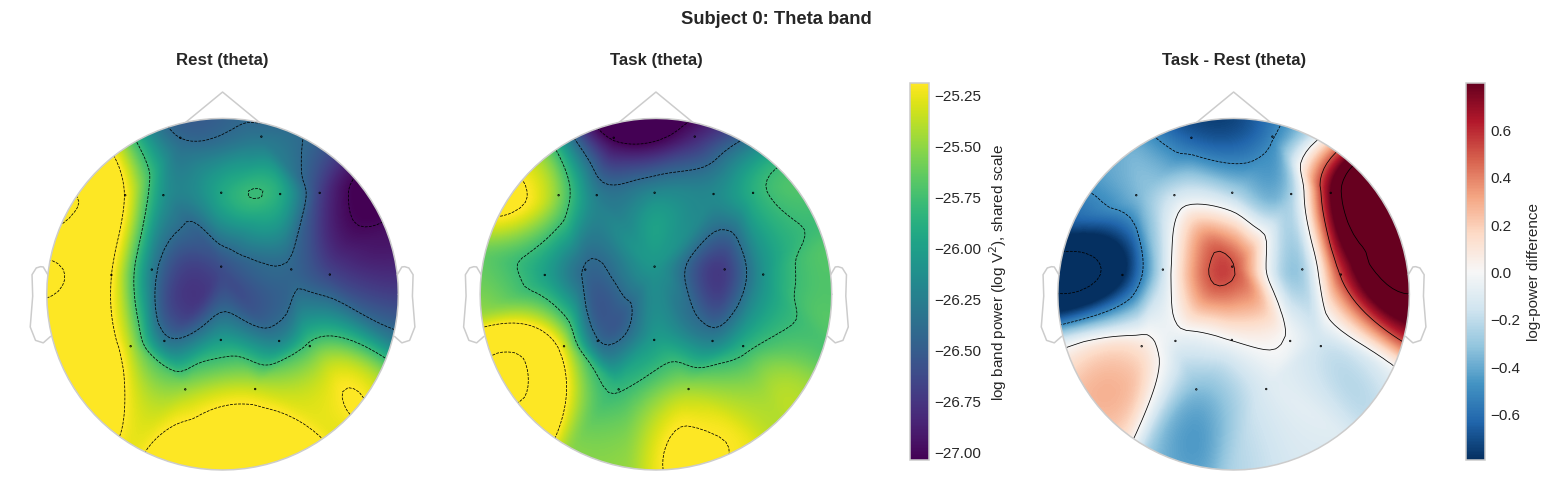


Theta, Task vs Rest by region (Welch t-test, Bonferroni-corrected):
  Occipital  diff = -0.179   p = 0.1558   p(bonf) = 0.7791 
  Frontal    diff = -0.054   p = 0.6683   p(bonf) = 1.0000 
  Temporal   diff = -0.047   p = 0.6382   p(bonf) = 1.0000 
  Central    diff = +0.034   p = 0.7306   p(bonf) = 1.0000 
  Parietal   diff = +0.016   p = 0.8850   p(bonf) = 1.0000 


In [14]:
demo_id = 0
demo_name = f'Subject{demo_id:02d}'
rest_file = os.path.join(data_path, f'{demo_name}_1.edf')
task_file = os.path.join(data_path, f'{demo_name}_2.edf')

if os.path.exists(rest_file) and os.path.exists(task_file):
    t0 = time.time()
    epochs_rest, epochs_task = preprocess_subject(rest_file, task_file)
    rest_data, task_data = epochs_rest.get_data(), epochs_task.get_data()
    sf = epochs_rest.info['sfreq']
    print(f'{demo_name}: {len(rest_data)} Rest and {len(task_data)} Task epochs (balanced) in {time.time() - t0:.1f}s')

    band = BAND_DEFS['theta']
    rest_avg = compute_band_power_per_channel(rest_data, sf, band).mean(axis=0)
    task_avg = compute_band_power_per_channel(task_data, sf, band).mean(axis=0)
    plot_subject_topomap(epochs_rest.info, rest_avg, task_avg, 'theta', demo_id)

    regions = region_summary_with_stats(rest_data, task_data, sf, epochs_rest.ch_names, 'theta')
    print('\nTheta, Task vs Rest by region (Welch t-test, Bonferroni-corrected):')
    for reg, s in regions.items():
        star = '*' if s['p_bonf'] < 0.05 else ''
        print(f"  {reg:10s} diff = {s['mean_diff']:+.3f}   p = {s['p_val']:.4f}   p(bonf) = {s['p_bonf']:.4f} {star}")
else:
    print(f'Demo files for {demo_name} not found; skipping.')

## 12. Cached, parallel pipeline: preprocessing + features for all subjects
One worker process per subject. Each subject's feature table **and** cleaned epochs are cached on disk under a name that includes a fingerprint of the preprocessing settings, so changing any setting automatically recomputes instead of silently reusing stale files.

In [15]:
def _cache_paths(cache_dir, subject_id, config):
    tag = config_hash(config)
    return (os.path.join(cache_dir, f'subject_{subject_id:02d}_{tag}_features.csv'),
            os.path.join(cache_dir, f'subject_{subject_id:02d}_{tag}_epochs.npz'))


def process_subject_cached(subject_id, rest_path, task_path, cache_dir, config=PREPROCESSING_CONFIG):
    """Preprocess one subject and extract features. Returns (feature_df, was_cached, seconds)."""
    feat_file, epo_file = _cache_paths(cache_dir, subject_id, config)
    if os.path.exists(feat_file) and os.path.exists(epo_file):
        return pd.read_csv(feat_file), True, 0.0

    t0 = time.time()
    epochs_rest, epochs_task = preprocess_subject(rest_path, task_path, config)
    ch_names, sfreq = epochs_rest.ch_names, epochs_rest.info['sfreq']
    X = np.concatenate([epochs_rest.get_data(), epochs_task.get_data()], axis=0)
    y = np.concatenate([np.zeros(len(epochs_rest)), np.ones(len(epochs_task))])

    df = pd.DataFrame([extract_all_features(X[i], sfreq, ch_names) for i in range(X.shape[0])])
    df['label'] = y
    df['subject'] = subject_id

    os.makedirs(cache_dir, exist_ok=True)
    np.savez_compressed(epo_file, X=X.astype(np.float32), y=y.astype(np.int8),
                        ch_names=np.array(ch_names), sfreq=float(sfreq))
    df.to_csv(feat_file, index=False)
    return df, False, time.time() - t0


def run_full_pipeline_cached(subject_pairs, cache_dir, config=PREPROCESSING_CONFIG, n_jobs=None):
    os.makedirs(cache_dir, exist_ok=True)
    n_jobs = n_jobs or max(1, (os.cpu_count() or 4) - 1)
    n_cached = sum(all(os.path.exists(p) for p in _cache_paths(cache_dir, sid, config)) for sid, _, _ in subject_pairs)
    print(f'{n_cached}/{len(subject_pairs)} subjects already cached for settings {config_hash(config)} in {cache_dir}')
    print(f'Processing with up to {n_jobs} worker process(es)...')

    try:
        ctx = mp.get_context('fork')   # keeps this notebook's functions available inside the workers
    except ValueError:
        ctx = mp.get_context()
        print(f"'fork' is unavailable here; using '{ctx.get_start_method()}'. Functions defined in a notebook "
              'cell may not be picklable under spawn -- move them into an importable .py module if this fails.')

    results, failures = [], []
    with ProcessPoolExecutor(max_workers=n_jobs, mp_context=ctx) as ex:
        futures = {ex.submit(process_subject_cached, sid, rp, tp, cache_dir, config): sid for sid, rp, tp in subject_pairs}
        with tqdm(total=len(futures), desc='Subjects', unit='subj') as pbar:
            for fut in as_completed(futures):
                sid = futures[fut]
                try:
                    df, was_cached, secs = fut.result()
                    results.append(df)
                    pbar.set_postfix_str(f"last: Subject {sid:02d} ({'cached' if was_cached else f'{secs:.0f}s'})")
                except Exception as e:
                    failures.append((sid, repr(e)))
                    pbar.set_postfix_str(f'last: Subject {sid:02d} FAILED')
                pbar.update(1)

    if failures:
        print(f'\n{len(failures)} subject(s) failed and were skipped:')
        for sid, err in failures:
            print(f'  Subject {sid:02d}: {err}')
    if not results:
        raise ValueError('No subjects processed successfully.')
    out = pd.concat(results, ignore_index=True)
    return out.sort_values(['subject', 'label'], kind='stable').reset_index(drop=True)   # keep epochs in time order

In [16]:
cache_dir = os.path.join(output_dir, 'subject_feature_cache')
feature_matrix_path = os.path.join(output_dir, 'eegmat_full_features.csv')
subject_info_path = os.path.join(data_path, 'subject-info.csv')
subject_info = pd.read_csv(subject_info_path)

subject_pairs = []
for subj in subject_info['Subject']:
    rest_p, task_p = os.path.join(data_path, f'{subj}_1.edf'), os.path.join(data_path, f'{subj}_2.edf')
    if os.path.exists(rest_p) and os.path.exists(task_p):
        subject_pairs.append((int(re.findall(r'\d+', subj)[0]), rest_p, task_p))
    else:
        print(f'  Warning: missing file(s) for {subj}, skipping.')
print(f'Found {len(subject_pairs)} complete subject pairs out of {len(subject_info)} subjects.')

feature_df = run_full_pipeline_cached(subject_pairs, cache_dir=cache_dir)
feature_df.to_csv(feature_matrix_path, index=False)
print(f'Feature matrix: {feature_df.shape[0]} epochs x {feature_df.shape[1] - 2} features -> {feature_matrix_path}')

feature_df_norm = normalize_features_per_subject(feature_df)

Found 36 complete subject pairs out of 36 subjects.
0/36 subjects already cached for settings 502d00f5 in /content/subject_feature_cache
Processing with up to 3 worker process(es)...


Subjects:   0%|          | 0/36 [00:00<?, ?subj/s]

Feature matrix: 1076 epochs x 1076 features -> /content/eegmat_full_features.csv


## 13. Exploratory plots

Topomaps (theta):   0%|          | 0/36 [00:00<?, ?subj/s]

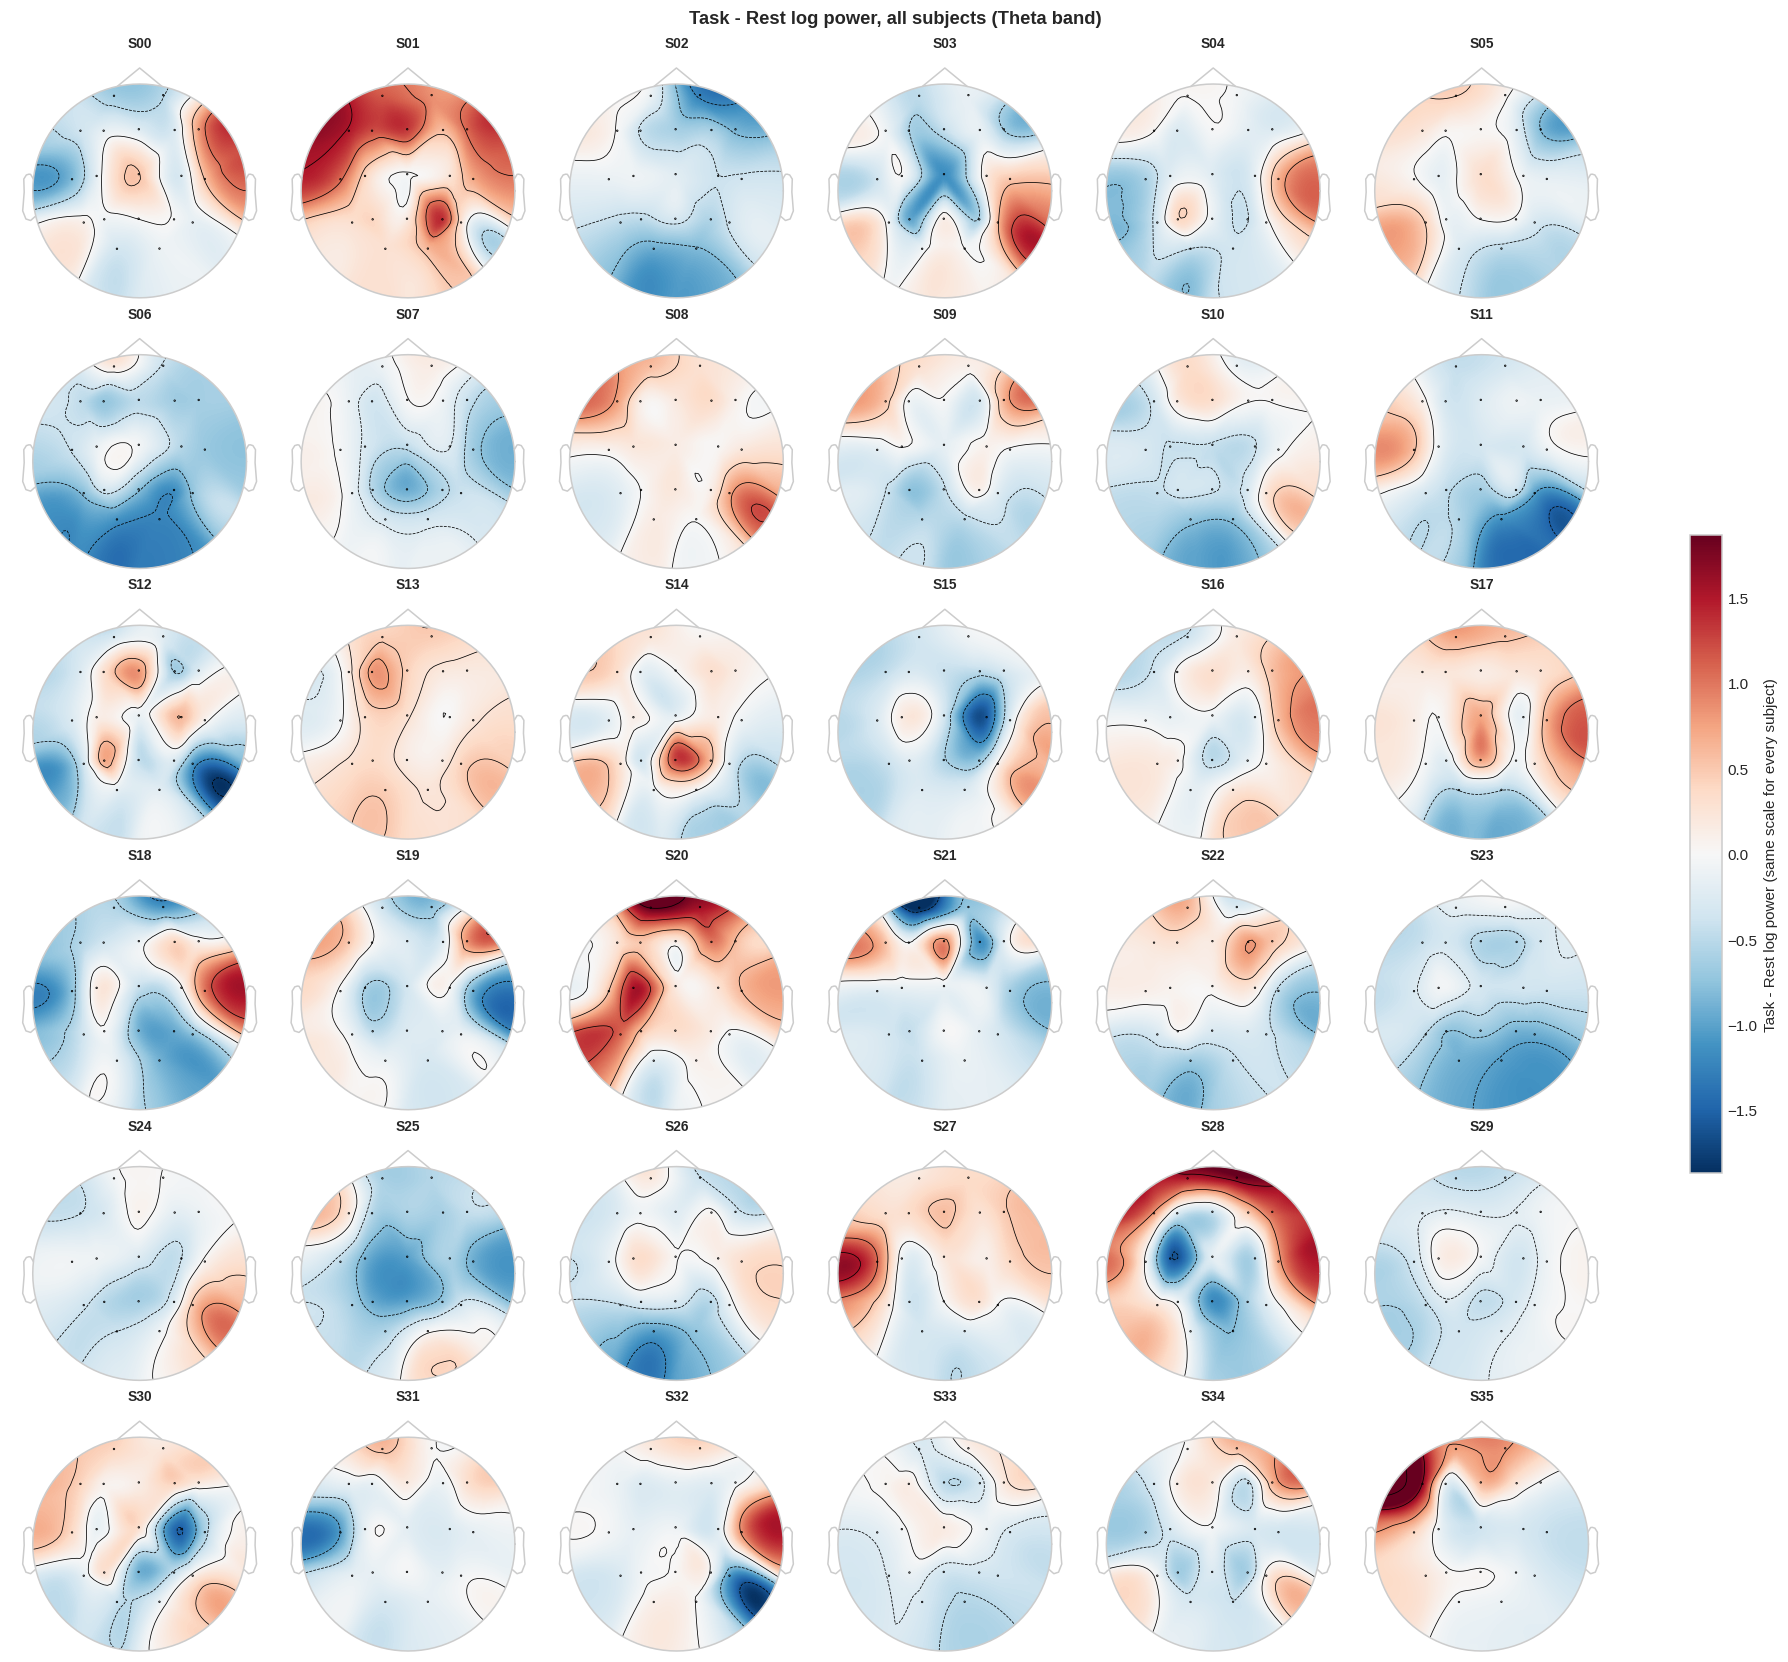

Per-subject topomaps saved to /content/topomaps


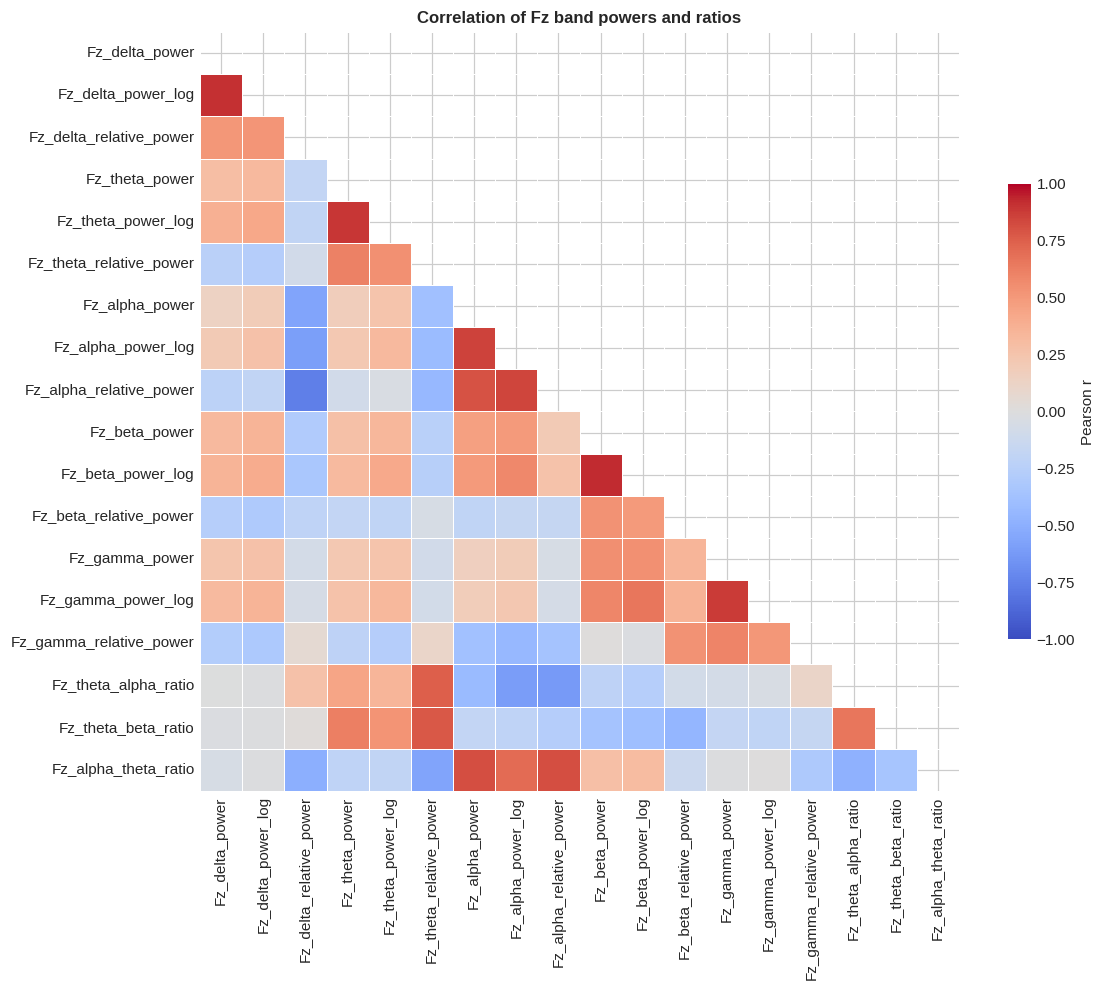

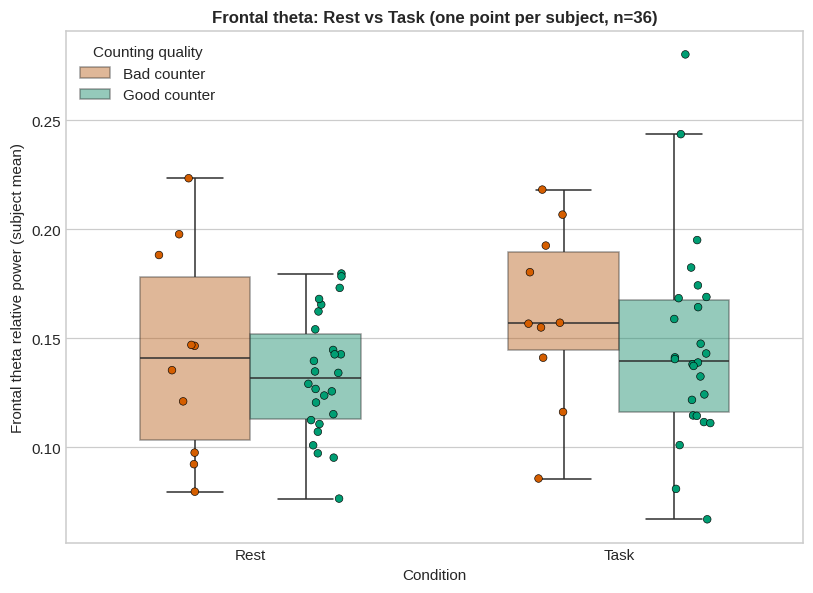

Task vs Rest (paired Wilcoxon, n=36): median change = +0.0102, p = 0.0105
Task-Rest change, good (n=26) vs bad (n=10) counters (Mann-Whitney): p = 0.5365


In [17]:
topomap_dir = os.path.join(output_dir, 'topomaps')
topo_diff_df = plot_all_subjects_topomaps(feature_df, band_name='theta', save_dir=topomap_dir)
print(f'Per-subject topomaps saved to {topomap_dir}')
plot_feature_correlation(feature_df, prefix='Fz')
analyze_good_vs_bad_counters(feature_df, subject_info_path)

## 14. Modelling
### 14a. Model helpers
Every model is a pipeline of **median imputation -> variance filter -> scaling -> ANOVA top-k selection -> classifier**. All steps are fitted inside each training fold, so the held-out subject never influences feature selection.

Hyperparameters are tuned once with grouped 5-fold CV on the same subjects that LOSO later evaluates, which leaves a small optimism in the LOSO numbers; the hold-out section (15) tunes on training subjects only and is the clean estimate.

In [18]:
def _pipe(clf, k=None, scale=True):
    """Leak-free preprocessing; every step is fitted on the training rows of each fold only."""
    steps = [('impute', SimpleImputer(strategy='median')), ('var', VarianceThreshold(1e-8))]
    if scale:
        steps.append(('scale', StandardScaler()))
    if k:
        steps.append(('select', SelectKBest(f_classif, k=k)))
    steps.append(('clf', clf))
    return Pipeline(steps)


def build_model_zoo(k=TOP_K, pos_weight=1.0, params=None):
    """name -> (family, pipeline). `params` holds tuned overrides from tune_model_zoo()."""
    params = params or {}
    def P(name, default):
        d = dict(default); d.update(params.get(name, {})); return d
    z = {
        'SVM-Linear': ('SVM', SVC(**P('SVM-Linear', dict(kernel='linear', C=0.01)),
                                  probability=True, class_weight='balanced', random_state=SEED)),
        'SVM-RBF': ('SVM', SVC(**P('SVM-RBF', dict(kernel='rbf', C=3.0, gamma='scale')),
                               probability=True, class_weight='balanced', random_state=SEED)),
        'LogReg-L2': ('Linear', LogisticRegression(C=0.05, max_iter=3000, class_weight='balanced')),
        'DecisionTree': ('Tree', DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                                        class_weight='balanced', random_state=SEED)),
        'ExtraTree (single)': ('Tree', ExtraTreeClassifier(max_depth=6, min_samples_leaf=10,
                                                           class_weight='balanced', random_state=SEED)),
        'Bagging (trees)': ('Tree ensemble', BaggingClassifier(DecisionTreeClassifier(max_depth=6),
                                              n_estimators=300, max_samples=0.8, max_features=0.5,
                                              random_state=SEED, n_jobs=1)),
        'RandomForest': ('Tree ensemble', RandomForestClassifier(**P('RandomForest', dict(
                                              n_estimators=500, min_samples_leaf=3, max_features='sqrt')),
                                              class_weight='balanced', random_state=SEED, n_jobs=1)),
        'ExtraTrees': ('Tree ensemble', ExtraTreesClassifier(**P('ExtraTrees', dict(
                                              n_estimators=500, min_samples_leaf=2, max_features='sqrt')),
                                              class_weight='balanced', random_state=SEED, n_jobs=1)),
        'AdaBoost': ('Boosting', AdaBoostClassifier(n_estimators=300, learning_rate=0.5, random_state=SEED)),
        'GradientBoosting': ('Boosting', GradientBoostingClassifier(**P('GradientBoosting', dict(
                                              n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8)),
                                              random_state=SEED)),
        'HistGradBoost': ('Boosting', HistGradientBoostingClassifier(**P('HistGradBoost', dict(
                                              learning_rate=0.05, max_iter=300, max_depth=4, l2_regularization=1.0)),
                                              class_weight='balanced', random_state=SEED)),
        'XGBoost': ('Boosting', XGBClassifier(**P('XGBoost', dict(
                                              n_estimators=300, max_depth=3, learning_rate=0.1, subsample=0.8,
                                              colsample_bytree=0.5, reg_lambda=3)),
                                              scale_pos_weight=pos_weight, eval_metric='logloss',
                                              random_state=SEED, n_jobs=1)),
    }
    return {n: (fam, _pipe(c, k)) for n, (fam, c) in z.items()}


TUNING_GRIDS = {
    'SVM-Linear': {'C': [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 1]},
    'SVM-RBF': {'C': [0.3, 1, 3, 10, 30], 'gamma': ['scale', 1e-4, 3e-4, 1e-3, 3e-3]},
    'RandomForest': {'n_estimators': [300, 600], 'min_samples_leaf': [1, 2, 5], 'max_features': ['sqrt', 'log2', 0.3]},
    'ExtraTrees': {'n_estimators': [300, 600], 'min_samples_leaf': [1, 2, 5], 'max_features': ['sqrt', 'log2', 0.3]},
    'GradientBoosting': {'n_estimators': [200, 400], 'learning_rate': [0.02, 0.05, 0.1], 'max_depth': [2, 3, 4], 'subsample': [0.6, 0.8]},
    'HistGradBoost': {'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 4, 6], 'l2_regularization': [0.1, 1, 5]},
    'XGBoost': {'n_estimators': [200, 400], 'max_depth': [2, 3, 4], 'learning_rate': [0.03, 0.05, 0.1], 'colsample_bytree': [0.3, 0.5, 0.8]},
}


def tune_model_zoo(X, y, groups, k=TOP_K, n_iter=TUNE_ITERS, only=None):
    """Grouped 5-fold random search per model (selection happens inside each fold)."""
    cv = list(GroupKFold(n_splits=min(5, len(np.unique(groups)))).split(X, y, groups))
    zoo = build_model_zoo(k, pos_weight=(len(y) - y.sum()) / max(y.sum(), 1))
    best = {}
    for name, grid in TUNING_GRIDS.items():
        if only and name not in only:
            continue
        search = RandomizedSearchCV(zoo[name][1], {f'clf__{p}': v for p, v in grid.items()},
                                    n_iter=min(n_iter, int(np.prod([len(v) for v in grid.values()]))),
                                    scoring='balanced_accuracy', cv=cv, random_state=SEED, n_jobs=-1)
        search.fit(X, y)
        best[name] = {p.replace('clf__', ''): v for p, v in search.best_params_.items()}
        print(f'  {name:17s} grouped-CV bal.acc = {search.best_score_:.3f}  {best[name]}')
    return best


def _fit_predict(est, Xtr, ytr, Xte):
    return clone(est).fit(Xtr, ytr).predict_proba(Xte)[:, 1]


def _balanced_per_subject(proba, subjects):
    """OPTIONAL transductive rule: label the top half of each subject's epochs (by P(task)) as Task.
    Only valid when the test recording is KNOWN to hold equal Rest and Task epochs. Report separately."""
    out = np.zeros(len(proba), dtype=int)
    for s in np.unique(subjects):
        m = subjects == s
        out[np.where(m)[0][proba[m] > np.median(proba[m])]] = 1
    return out


def _score(y, proba, subjects):
    raw = (proba > 0.5).astype(int)
    subs = np.unique(subjects)
    per_bal = [balanced_accuracy_score(y[subjects == s], raw[subjects == s]) for s in subs]
    per_auc = [roc_auc_score(y[subjects == s], proba[subjects == s]) for s in subs if len(np.unique(y[subjects == s])) == 2]
    return {'bal_acc (pooled)': balanced_accuracy_score(y, raw),
            'bal_acc (per-subj mean)': np.mean(per_bal), 'per-subj std': np.std(per_bal),
            'auc (pooled)': roc_auc_score(y, proba), 'auc (per-subj mean)': np.mean(per_auc) if per_auc else np.nan,
            'f1_task': f1_score(y, raw), 'mcc': matthews_corrcoef(y, raw),
            'bal_acc (median-split/subj)': balanced_accuracy_score(y, _balanced_per_subject(proba, subjects))}


def run_model_zoo_loso(feature_df, k=TOP_K, tune=RUN_TUNING, n_jobs=-1, exclude_ids=()):
    """Leave-One-Subject-Out over every model plus soft-vote ensembles of the out-of-fold probabilities."""
    df = feature_df[~feature_df['subject'].isin(list(exclude_ids))].reset_index(drop=True)
    cols = [c for c in df.columns if c not in ('label', 'subject')]
    X, y, g = df[cols], df['label'].values.astype(int), df['subject'].values
    k = min(k, len(cols))
    print(f'LOSO on {len(np.unique(g))} subjects, {len(df)} epochs, {len(cols)} features -> in-fold top-{k}')
    params = None
    if tune:
        print('Tuning (grouped 5-fold on these subjects; small optimism):')
        params = tune_model_zoo(X, y, g, k)
    zoo = build_model_zoo(k, (len(y) - y.sum()) / max(y.sum(), 1), params)

    splits = list(LeaveOneGroupOut().split(X, y, g))
    oof = {}
    for name, (fam, est) in zoo.items():
        res = Parallel(n_jobs=n_jobs)(delayed(_fit_predict)(est, X.iloc[tr], y[tr], X.iloc[te]) for tr, te in splits)
        p = np.zeros(len(y))
        for (tr, te), r in zip(splits, res):
            p[te] = r
        oof[name] = p
        print(f'  {name:18s} bal.acc = {balanced_accuracy_score(y, p > .5):.3f}   auc = {roc_auc_score(y, p):.3f}')

    fam = {n: f for n, (f, _) in zoo.items()}
    rank = sorted(oof, key=lambda n: -roc_auc_score(y, oof[n]))
    oof['Ensemble: all models'] = np.mean([oof[n] for n in zoo], axis=0)
    oof['Ensemble: SVMs'] = np.mean([oof[n] for n in zoo if fam[n] == 'SVM'], axis=0)
    oof['Ensemble: tree models'] = np.mean([oof[n] for n in zoo if fam[n] in ('Tree ensemble', 'Boosting')], axis=0)
    oof['Ensemble: SVM + boosting'] = np.mean([oof[n] for n in ('SVM-Linear', 'SVM-RBF', 'XGBoost', 'GradientBoosting', 'HistGradBoost')], axis=0)
    oof['Ensemble: top-3 by LOSO AUC (post-hoc, optimistic)'] = np.mean([oof[n] for n in rank[:3]], axis=0)

    table = pd.DataFrame({n: _score(y, p, g) for n, p in oof.items()}).T
    table.insert(0, 'family', [fam.get(n, 'Ensemble') for n in table.index])
    table = table.sort_values('bal_acc (per-subj mean)', ascending=False)
    print('\n=== LOSO results (sorted by per-subject mean balanced accuracy) ===')
    print(table.round(3).to_string())

    fig, ax = plt.subplots(figsize=(9, 7))
    t = table.iloc[::-1]
    ax.barh(t.index, t['bal_acc (per-subj mean)'], xerr=t['per-subj std'], color='teal', alpha=0.85, error_kw=dict(alpha=.4))
    ax.axvline(0.5, ls='--', c='gray'); ax.set_xlim(0.3, 1.05)
    ax.set_xlabel('Balanced accuracy (mean over held-out subjects, error bars = SD across subjects)')
    ax.set_title('LOSO: model comparison')
    plt.tight_layout(); plt.show()
    return table, oof, params, df


def plot_loso_roc_cm(oof, df, names=('RandomForest', 'XGBoost')):
    """Per-subject ROC curves with mean +/- SD, plus the pooled confusion matrix, for each named model."""
    y, g = df['label'].values.astype(int), df['subject'].values
    fig, axes = plt.subplots(2, len(names), figsize=(6.2 * len(names), 10.5), squeeze=False)
    grid = np.linspace(0, 1, 101)
    for j, name in enumerate(names):
        p, ax = oof[name], axes[0, j]
        tprs, aucs = [], []
        for s in np.unique(g):
            m = g == s
            if len(np.unique(y[m])) < 2:
                continue
            fpr, tpr, _ = roc_curve(y[m], p[m])
            t = np.interp(grid, fpr, tpr); t[0] = 0.0
            tprs.append(t); aucs.append(auc(fpr, tpr))
            ax.plot(fpr, tpr, lw=0.9, alpha=0.35, color='tab:blue')
        mean_t, sd = np.mean(tprs, axis=0), np.std(tprs, axis=0)
        mean_t[-1] = 1.0
        ax.fill_between(grid, np.clip(mean_t - sd, 0, 1), np.clip(mean_t + sd, 0, 1), color='tab:blue', alpha=0.15, label='+/-1 SD across subjects')
        ax.plot(grid, mean_t, color='navy', lw=2.4, label=f'Mean ROC (per-subject AUC {np.mean(aucs):.2f} $\\pm$ {np.std(aucs):.2f})')
        ax.plot([0, 1], [0, 1], '--', color='gray', label='Chance')
        ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
        ax.set_title(f'{name}: ROC per held-out subject'); ax.legend(loc='lower right', fontsize=9)
        ConfusionMatrixDisplay(confusion_matrix(y, (p > 0.5).astype(int)), display_labels=['Rest', 'Task']).plot(
            ax=axes[1, j], cmap='Blues', values_format='d', colorbar=False)
        axes[1, j].set_title(f'{name}: pooled confusion matrix (LOSO)'); axes[1, j].grid(False)
    plt.tight_layout(); plt.show()
    for name in names:
        print(f'\n{name} (LOSO, pooled):')
        print(classification_report(y, (oof[name] > 0.5).astype(int), target_names=['Rest', 'Task'], zero_division=0))


def oof_shap_importance(feature_df, top=20, n_splits=5):
    """DESCRIPTIVE ranking: mean |SHAP| of an XGBoost model on subjects it was NOT trained on (grouped CV).
    It is not used to select features for any reported score. Bars are red for artifact-prone channels."""
    from matplotlib.patches import Patch
    X = feature_df.drop(columns=['label', 'subject'])
    y, g = feature_df['label'].values.astype(int), feature_df['subject'].values
    gkf = GroupKFold(n_splits=min(n_splits, len(np.unique(g))))
    imp = np.zeros(X.shape[1]); n_folds = 0
    for tr, te in tqdm(list(gkf.split(X, y, g)), desc='SHAP folds', unit='fold'):
        m = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, eval_metric='logloss',
                          random_state=SEED, n_jobs=-1).fit(X.iloc[tr], y[tr])
        imp += np.abs(shap.TreeExplainer(m).shap_values(X.iloc[te])).mean(axis=0)
        n_folds += 1
    imp = pd.Series(imp / n_folds, index=X.columns).sort_values(ascending=False)

    top_imp = imp.head(top).iloc[::-1]
    colors = ['firebrick' if feature_channel(c) in ARTIFACT_PRONE_CHANNELS else 'teal' for c in top_imp.index]
    fig, ax = plt.subplots(figsize=(8.5, 7))
    ax.barh(top_imp.index, top_imp.values, color=colors)
    ax.set_xlabel('Mean |SHAP value| on unseen subjects')
    ax.set_title(f'Top {top} features (descriptive; not used for selection)')
    ax.legend(handles=[Patch(color='firebrick', label='frontal-pole / temporal channel (artifact-prone)'),
                       Patch(color='teal', label='other')], loc='lower right', fontsize=9)
    plt.tight_layout(); plt.show()
    share = np.mean([feature_channel(c) in ARTIFACT_PRONE_CHANNELS for c in imp.head(top).index])
    print(f'{share:.0%} of the top-{top} features come from artifact-prone channels '
          f'({len(ARTIFACT_PRONE_CHANNELS)} of {len(STANDARD_CHANNELS)} channels = {len(ARTIFACT_PRONE_CHANNELS) / len(STANDARD_CHANNELS):.0%} of the scalp).')
    return imp


def descriptive_shap(feature_df, k=TOP_K, params=None, max_display=15):
    """SHAP summary of an XGBoost pipeline fitted on ALL subjects (explanation only, not an accuracy estimate)."""
    X = feature_df.drop(columns=['label', 'subject'])
    y = feature_df['label'].values.astype(int)
    pipe = build_model_zoo(min(k, X.shape[1]), (len(y) - y.sum()) / max(y.sum(), 1), params)['XGBoost'][1].fit(X, y)
    names = X.columns[pipe.named_steps['var'].get_support()][pipe.named_steps['select'].get_support()]
    Xt = pd.DataFrame(pipe[:-1].transform(X), columns=names)
    sv = shap.TreeExplainer(pipe.named_steps['clf']).shap_values(Xt)
    plt.figure(figsize=(8, 6))
    shap.summary_plot(sv, Xt, plot_type='bar', max_display=max_display, show=False)
    plt.title('Mean |SHAP| (XGBoost fitted on all subjects; explanation only)'); plt.tight_layout(); plt.show()
    plt.figure(figsize=(9, 6.5))
    shap.summary_plot(sv, Xt, max_display=max_display, show=False)
    plt.title('Direction and spread of each feature\'s effect'); plt.tight_layout(); plt.show()

### 14b. LOSO evaluation (leave-one-subject-out)
Each of the subjects is held out in turn; the model is trained on all others. This is the main estimate of how well the approach generalizes to a new person.

LOSO on 36 subjects, 1076 epochs, 1076 features -> in-fold top-150
Tuning (grouped 5-fold on these subjects; small optimism):
  SVM-Linear        grouped-CV bal.acc = 0.738  {'C': 0.03}
  SVM-RBF           grouped-CV bal.acc = 0.745  {'gamma': 0.0003, 'C': 30}
  RandomForest      grouped-CV bal.acc = 0.733  {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
  ExtraTrees        grouped-CV bal.acc = 0.733  {'n_estimators': 600, 'min_samples_leaf': 2, 'max_features': 0.3}
  GradientBoosting  grouped-CV bal.acc = 0.747  {'subsample': 0.6, 'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.1}
  HistGradBoost     grouped-CV bal.acc = 0.736  {'max_depth': 4, 'learning_rate': 0.05, 'l2_regularization': 0.1}
  XGBoost           grouped-CV bal.acc = 0.742  {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.5}
  SVM-Linear         bal.acc = 0.732   auc = 0.812
  SVM-RBF            bal.acc = 0.737   auc = 0.820
  LogReg-L2          bal.acc = 0.

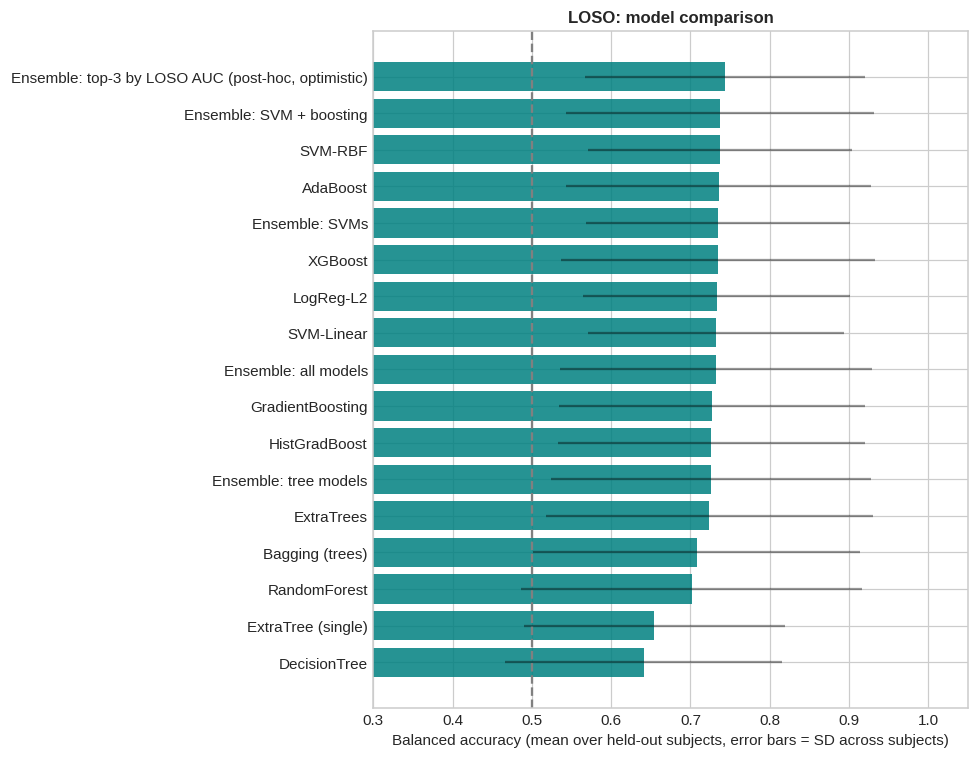

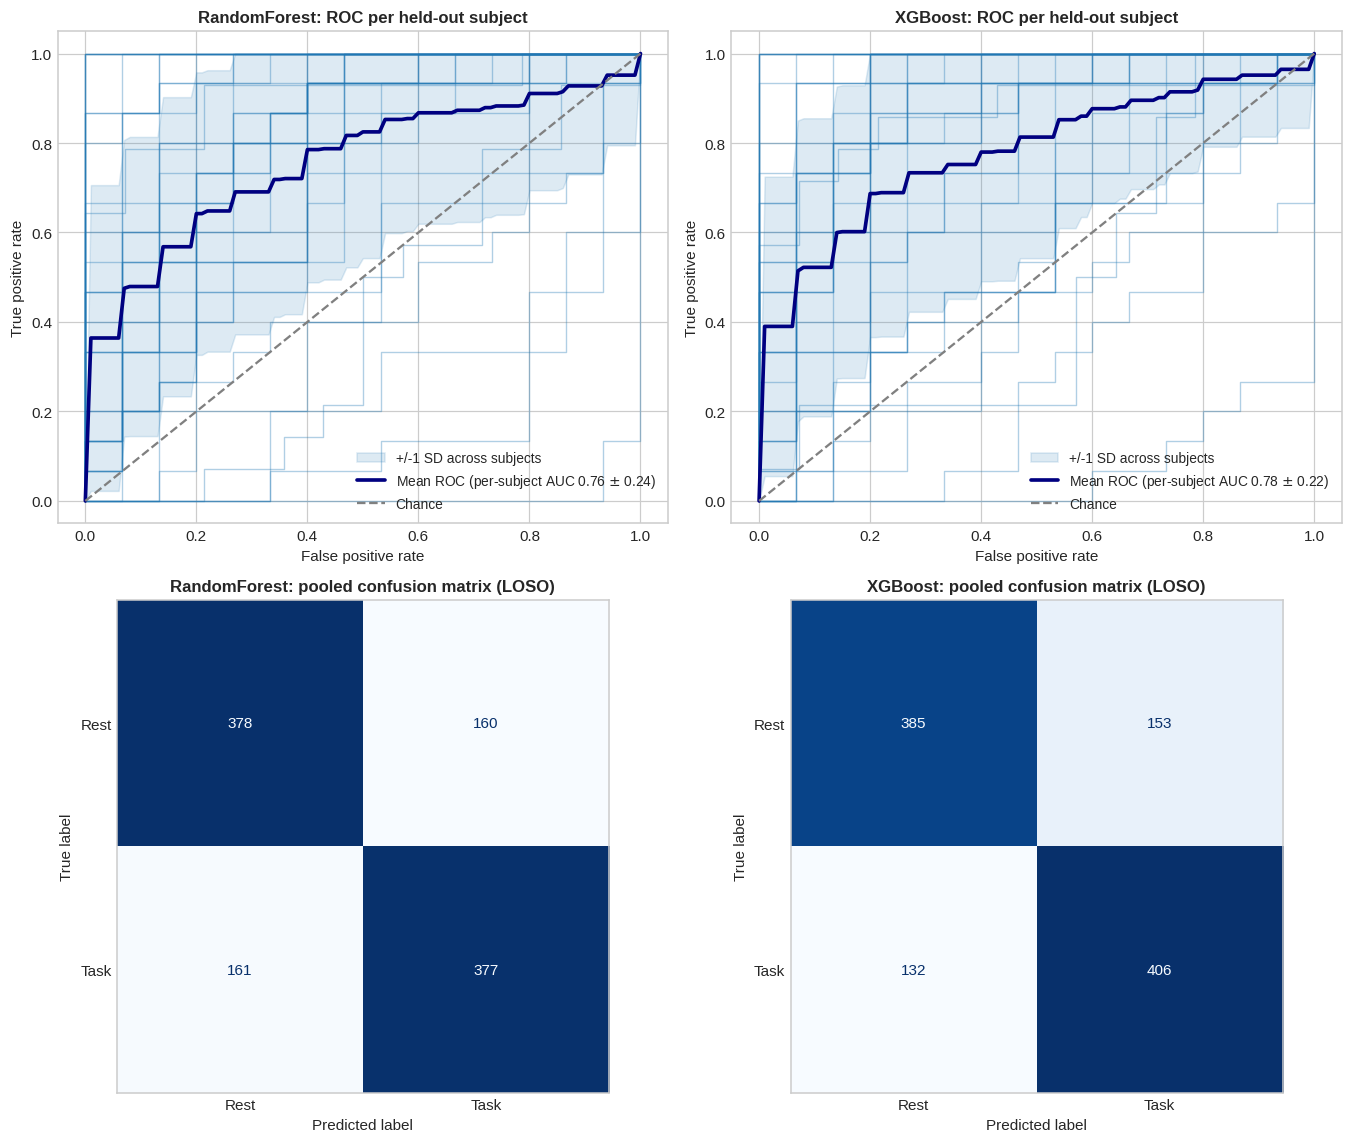


RandomForest (LOSO, pooled):
              precision    recall  f1-score   support

        Rest       0.70      0.70      0.70       538
        Task       0.70      0.70      0.70       538

    accuracy                           0.70      1076
   macro avg       0.70      0.70      0.70      1076
weighted avg       0.70      0.70      0.70      1076


XGBoost (LOSO, pooled):
              precision    recall  f1-score   support

        Rest       0.74      0.72      0.73       538
        Task       0.73      0.75      0.74       538

    accuracy                           0.74      1076
   macro avg       0.74      0.74      0.74      1076
weighted avg       0.74      0.74      0.74      1076



In [19]:
loso_table, loso_oof, tuned_params, loso_df = run_model_zoo_loso(feature_df_norm, k=TOP_K, tune=RUN_TUNING)
loso_table.to_csv(os.path.join(output_dir, 'loso_model_zoo_results.csv'))
plot_loso_roc_cm(loso_oof, loso_df, names=('RandomForest', 'XGBoost'))

### 14c. What drives the predictions?
Red bars are features from frontal-pole and temporal electrodes, where eye movements and jaw/scalp muscle tension leave the strongest traces. A large red share means the classifier may be reading task-related *artifacts* (frowning, blinking, clenching) rather than brain activity; Section 16 tests that directly.

SHAP folds:   0%|          | 0/5 [00:00<?, ?fold/s]

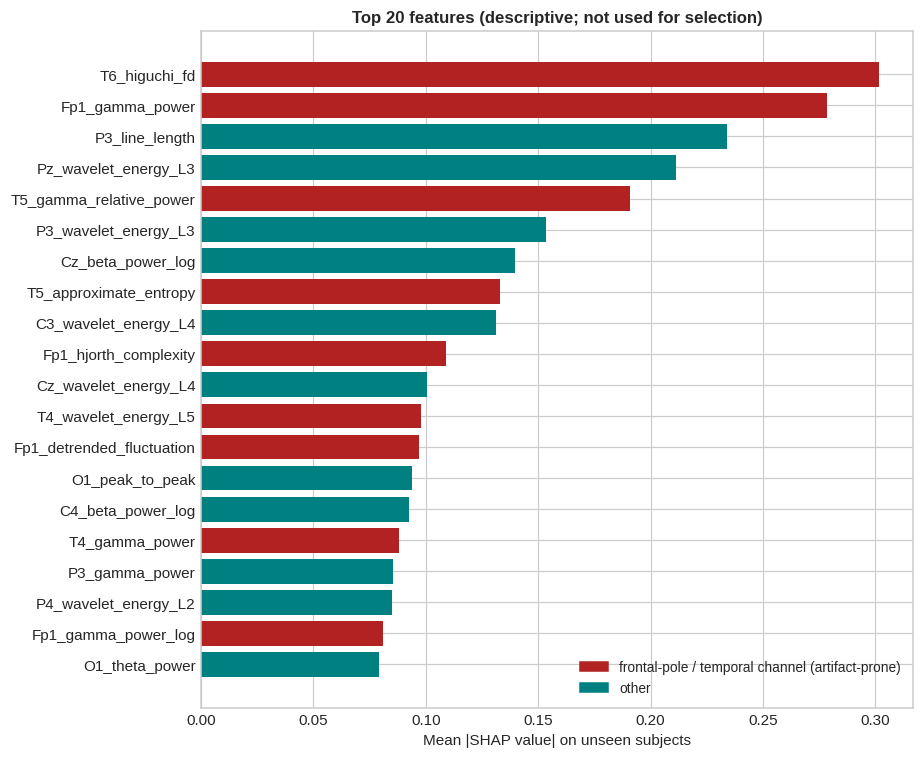

45% of the top-20 features come from artifact-prone channels (8 of 19 channels = 42% of the scalp).


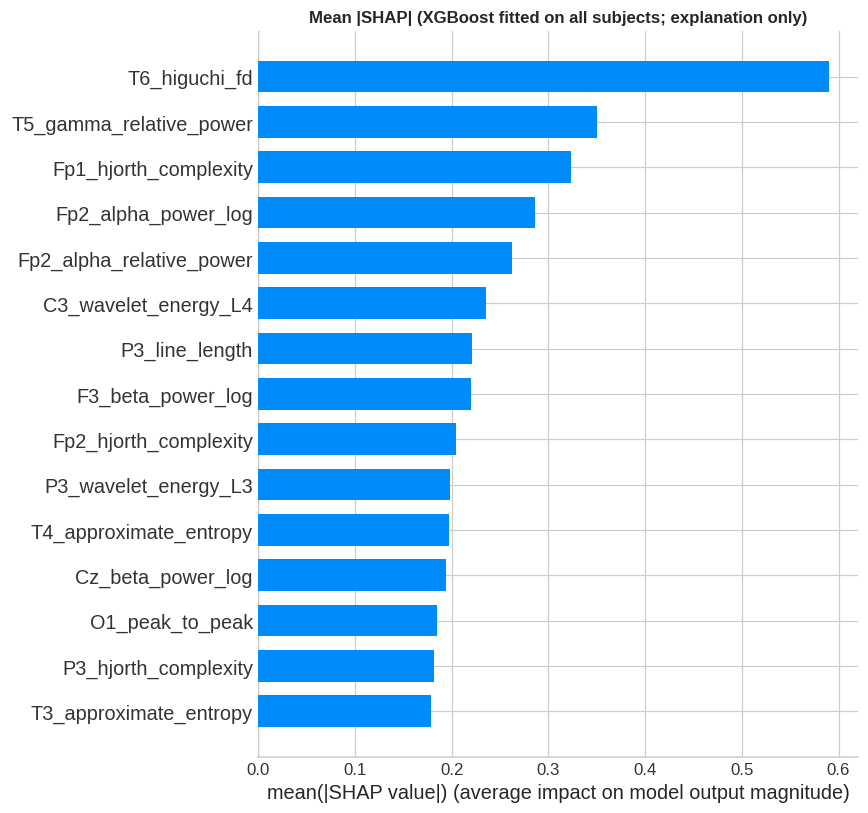

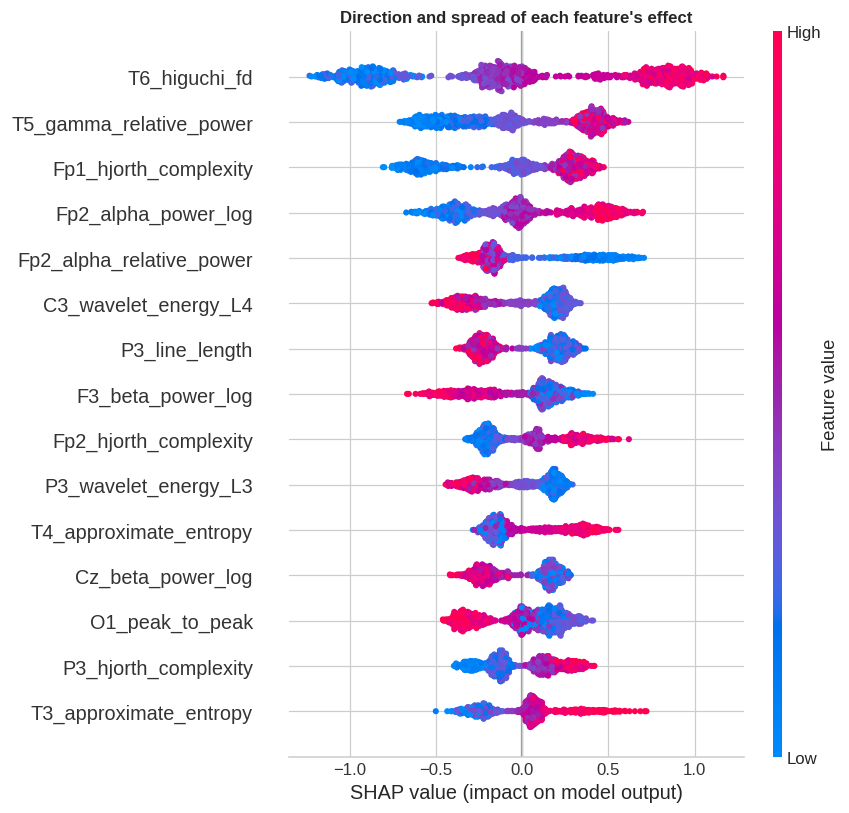

In [20]:
shap_importance = oof_shap_importance(feature_df_norm, top=20)
descriptive_shap(feature_df_norm, k=TOP_K, params=tuned_params)

## 15. Clean hold-out test: Subject01, Subject22, Subject35
Everything that learns (imputation, scaling, feature selection, hyperparameters, model choice) uses the other subjects only. The final model is chosen by grouped CV on the training subjects, never by hold-out score. Three subjects are about 90 epochs, so these numbers are noisy: **the LOSO result is the headline estimate**. Smoothed metrics assume neighbouring epochs of one recording are available; report the raw numbers as the strict result.

Saved: `holdout_epoch_predictions.csv`, `holdout_model_comparison.csv`, `holdout_per_subject_results.csv`, `best_holdout_model.joblib`.

Train: 33 subjects / 988 epochs | Test: Subject01, Subject22, Subject35 / 88 epochs | 1076 features


Grouped CV on training subjects:   0%|          | 0/10 [00:00<?, ?it/s]


Grouped CV on the training subjects (used to choose the final model):
                    model  cv_bal_acc  cv_auc
            SVM-RBF (all)       0.746   0.837
Ensemble: soft vote (all)       0.744   0.829
            XGBoost (all)       0.739   0.804
             LogReg (all)       0.734   0.806
           LogReg (top-k)       0.729   0.808
       RandomForest (all)       0.723   0.804
         ExtraTrees (all)       0.721   0.804
          XGBoost (top-k)       0.716   0.787
     RandomForest (top-k)       0.712   0.780
          SVM-RBF (top-k)       0.699   0.787

-> Chosen by grouped CV: SVM-RBF (all)


Fit + predict hold-out:   0%|          | 0/10 [00:00<?, ?it/s]


=== Hold-out results, pooled over the hold-out subjects ===
                    model   predictions  bal_acc   auc  f1_task   mcc
            SVM-RBF (all)           raw    0.920 0.974    0.921 0.841
             LogReg (all)           raw    0.886 0.934    0.886 0.773
            XGBoost (all)           raw    0.886 0.963    0.889 0.774
Ensemble: soft vote (all)           raw    0.886 0.958    0.889 0.774
         ExtraTrees (all)           raw    0.818 0.909    0.830 0.642
       RandomForest (all)           raw    0.807 0.903    0.817 0.618
          SVM-RBF (top-k)           raw    0.739 0.811    0.753 0.480
     RandomForest (top-k)           raw    0.739 0.821    0.753 0.480
           LogReg (top-k)           raw    0.727 0.809    0.733 0.455
          XGBoost (top-k)           raw    0.727 0.819    0.733 0.455
            SVM-RBF (all) smoothed(w=3)    0.977 0.998    0.977 0.956
             LogReg (all) smoothed(w=3)    0.955 0.996    0.953 0.910
Ensemble: soft vote (all) smo

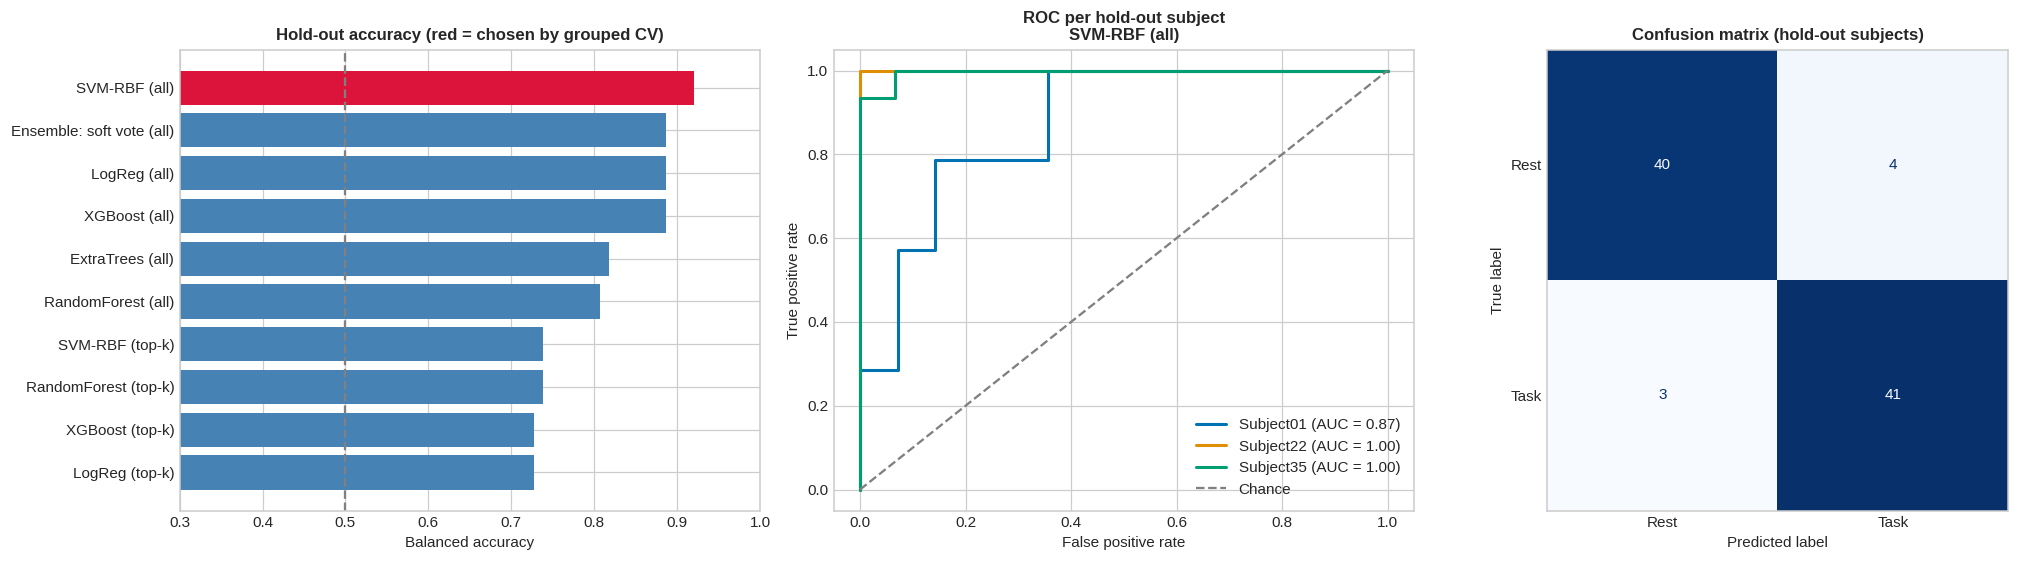

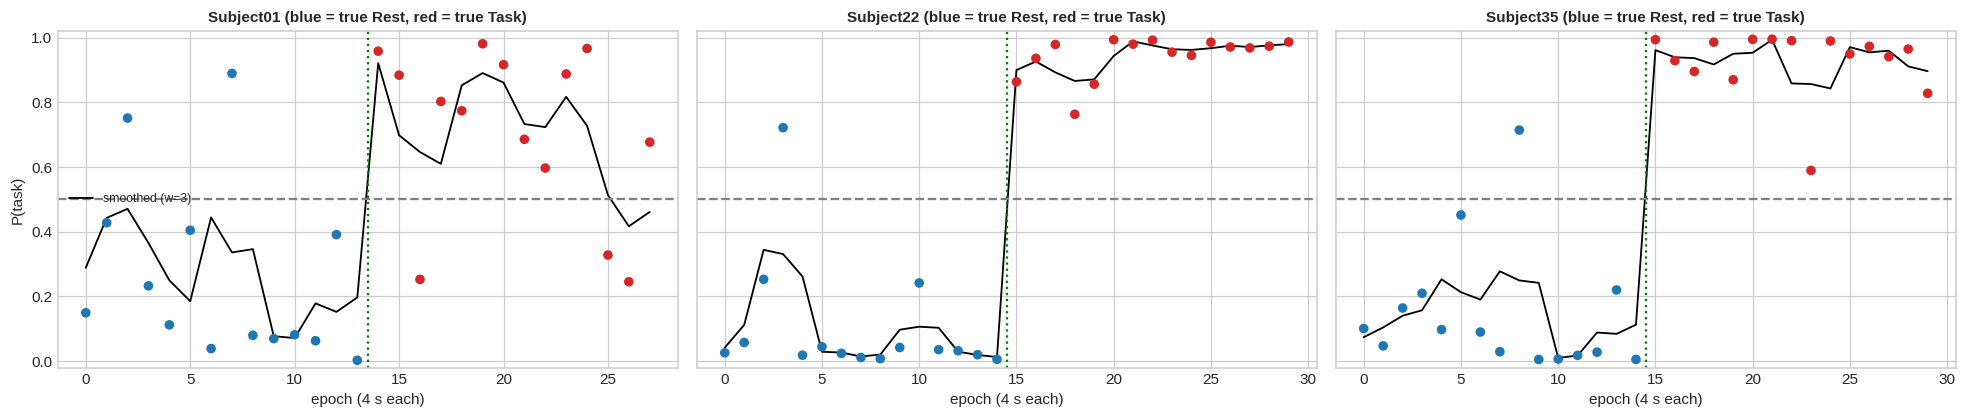

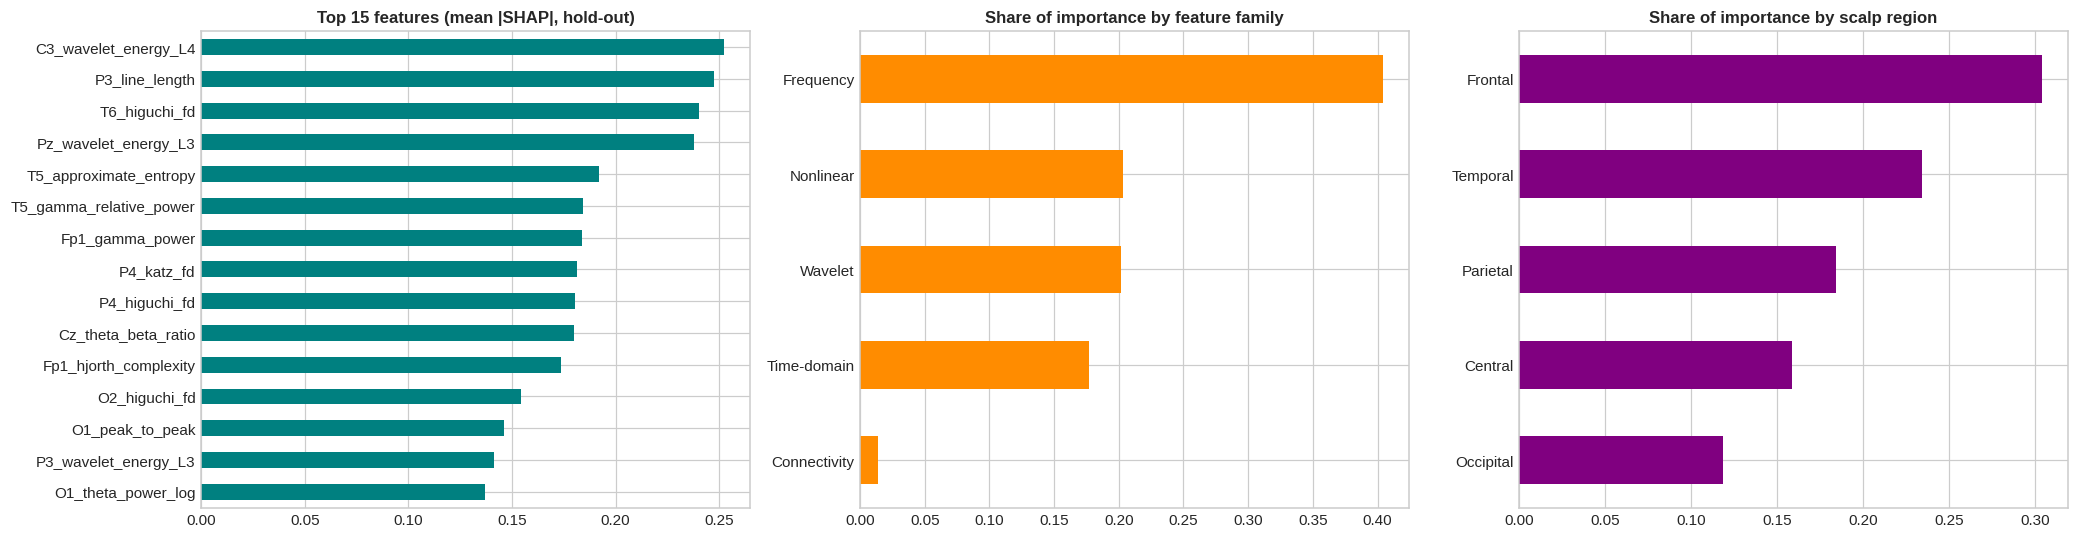

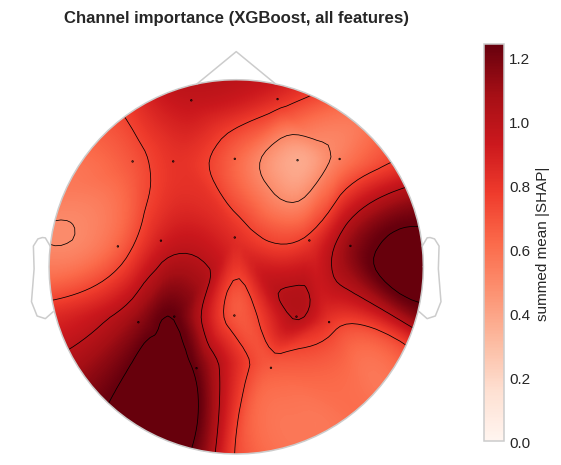


Saved predictions, comparison tables and best_holdout_model.joblib to /content

Counting quality of the hold-out subjects:
  Subject  Age Gender  Count quality
Subject01   18      F              1
Subject22   19      F              0
Subject35   17      F              1


In [21]:
def _feature_family(col):
    if col.startswith(('corr_', 'plv_', 'coherence_')):
        return 'Connectivity'
    name = col.split('_', 1)[1] if '_' in col else col
    if name.startswith('wavelet'):
        return 'Wavelet'
    if any(b in name for b in BAND_DEFS) or name.startswith(('spectral', 'peak_freq', 'engagement')) or 'ratio' in name:
        return 'Frequency'
    if name in ('permutation_entropy', 'svd_entropy', 'approximate_entropy', 'sample_entropy', 'petrosian_fd',
                'katz_fd', 'higuchi_fd', 'detrended_fluctuation', 'num_zero_crossings', 'lz_complexity'):
        return 'Nonlinear'
    return 'Time-domain'


def _make_models(k, pos_weight):
    """name -> pipeline. 'top-k' models select features INSIDE each fold (ANOVA), so cross-validation
    comparisons between 'all' and 'top-k' are fair."""
    lr = lambda: LogisticRegression(C=0.05, max_iter=3000, class_weight='balanced')
    svm = lambda: SVC(C=1.0, kernel='rbf', gamma='scale', probability=True, class_weight='balanced', random_state=SEED)
    et = lambda: ExtraTreesClassifier(n_estimators=500, min_samples_leaf=3, max_features='sqrt',
                                      class_weight='balanced', random_state=SEED, n_jobs=-1)
    rf = lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt',
                                        class_weight='balanced', random_state=SEED, n_jobs=-1)
    xgb = lambda: XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                                reg_lambda=3, random_state=SEED, eval_metric='logloss',
                                scale_pos_weight=pos_weight, n_jobs=-1)
    models = {
        'LogReg (all)': _pipe(lr()), 'SVM-RBF (all)': _pipe(svm()), 'ExtraTrees (all)': _pipe(et()),
        'RandomForest (all)': _pipe(rf()), 'XGBoost (all)': _pipe(xgb()),
        'LogReg (top-k)': _pipe(lr(), k), 'SVM-RBF (top-k)': _pipe(svm(), k),
        'RandomForest (top-k)': _pipe(rf(), k), 'XGBoost (top-k)': _pipe(xgb(), k),
    }
    members = [('lr', _pipe(lr())), ('svm', _pipe(svm())), ('et', _pipe(et())), ('xgb', _pipe(xgb()))]
    models['Ensemble: soft vote (all)'] = VotingClassifier(members, voting='soft', n_jobs=1)
    return models


def _smooth(proba, group_key, window=3):
    """Centered rolling mean over neighbouring epochs of one recording (rows must be in time order)."""
    return pd.Series(proba).groupby(group_key).transform(lambda x: x.rolling(window, center=True, min_periods=1).mean()).values


def extended_holdout_prediction(feature_df_norm, holdout_ids=HOLDOUT_SUBJECT_IDS, k=TOP_K, smooth_window=3, save_dir=None):
    holdout_ids = list(holdout_ids)
    save_dir = save_dir or output_dir
    missing = [s for s in holdout_ids if s not in set(feature_df_norm['subject'].unique())]
    if missing:
        raise ValueError(f'Hold-out subject id(s) {missing} not found in the feature matrix.')

    feature_cols = [c for c in feature_df_norm.columns if c not in ('label', 'subject')]
    is_test = feature_df_norm['subject'].isin(holdout_ids)
    train_df, test_df = feature_df_norm[~is_test].reset_index(drop=True), feature_df_norm[is_test].reset_index(drop=True)
    y_train, y_test = train_df['label'].values.astype(int), test_df['label'].values.astype(int)
    g_train = train_df['subject'].values
    k = min(k, len(feature_cols))
    print(f'Train: {train_df.subject.nunique()} subjects / {len(train_df)} epochs | '
          f'Test: {", ".join(f"Subject{int(s):02d}" for s in sorted(holdout_ids))} / {len(test_df)} epochs | {len(feature_cols)} features')

    models = _make_models(k, (len(y_train) - y_train.sum()) / max(y_train.sum(), 1))

    # Model selection: grouped CV on TRAIN subjects only
    gkf = GroupKFold(n_splits=min(5, len(np.unique(g_train))))
    cv_rows = []
    for name, est in tqdm(models.items(), desc='Grouped CV on training subjects'):
        p = cross_val_predict(est, train_df[feature_cols], y_train, groups=g_train, cv=gkf, method='predict_proba')[:, 1]
        cv_rows.append({'model': name, 'cv_bal_acc': balanced_accuracy_score(y_train, p > 0.5), 'cv_auc': roc_auc_score(y_train, p)})
    cv_df = pd.DataFrame(cv_rows).sort_values('cv_bal_acc', ascending=False).reset_index(drop=True)
    best_name = cv_df.loc[0, 'model']
    print('\nGrouped CV on the training subjects (used to choose the final model):')
    print(cv_df.round(3).to_string(index=False))
    print(f'\n-> Chosen by grouped CV: {best_name}')

    # Fit on all training subjects, score the hold-out subjects once
    fitted, pred_store, summary_rows, per_subj_rows = {}, {}, [], []
    order_key = (test_df['subject'].astype(str) + '_' + test_df['label'].astype(int).astype(str)).values
    for name, est in tqdm(models.items(), desc='Fit + predict hold-out'):
        est.fit(train_df[feature_cols], y_train)
        fitted[name] = est
        proba = est.predict_proba(test_df[feature_cols])[:, 1]
        pred_store[name] = proba
        for tag, pr in (('raw', proba), (f'smoothed(w={smooth_window})', _smooth(proba, order_key, smooth_window))):
            pred = (pr > 0.5).astype(int)
            summary_rows.append({'model': name, 'predictions': tag, 'bal_acc': balanced_accuracy_score(y_test, pred),
                                 'auc': roc_auc_score(y_test, pr), 'f1_task': f1_score(y_test, pred),
                                 'mcc': matthews_corrcoef(y_test, pred)})
        for sid in holdout_ids:
            m = (test_df['subject'] == sid).values
            pred = (proba[m] > 0.5).astype(int)
            per_subj_rows.append({'model': name, 'subject': f'Subject{sid:02d}', 'n_epochs': int(m.sum()),
                                  'accuracy': float((pred == y_test[m]).mean()),
                                  'bal_acc': balanced_accuracy_score(y_test[m], pred),
                                  'auc': roc_auc_score(y_test[m], proba[m]) if len(np.unique(y_test[m])) == 2 else np.nan})
    summary, per_subject = pd.DataFrame(summary_rows), pd.DataFrame(per_subj_rows)
    print('\n=== Hold-out results, pooled over the hold-out subjects ===')
    print(summary.sort_values(['predictions', 'bal_acc'], ascending=[True, False]).round(3).to_string(index=False))

    best_proba = pred_store[best_name]
    best_proba_s = _smooth(best_proba, order_key, smooth_window)
    best_pred = (best_proba > 0.5).astype(int)
    print(f'\n=== Per-subject results, chosen model: {best_name} ===')
    print(per_subject[per_subject.model == best_name].drop(columns='model').round(3).to_string(index=False))
    print('\nClassification report (chosen model, raw epoch predictions):')
    print(classification_report(y_test, best_pred, target_names=['Rest', 'Task'], zero_division=0))

    rec = (test_df.assign(p=best_proba).groupby(['subject', 'label']).p.mean().reset_index().rename(columns={'p': 'mean_P(task)'}))
    rec['recording'] = rec['label'].map({0: 'Rest', 1: 'Task'})
    rec['predicted'] = np.where(rec['mean_P(task)'] > 0.5, 'Task', 'Rest')
    rec['correct'] = rec['recording'] == rec['predicted']
    rec['subject'] = rec['subject'].map(lambda s: f'Subject{int(s):02d}')
    print('\nRecording-level decision (mean P(task) across each recording):')
    print(rec[['subject', 'recording', 'mean_P(task)', 'predicted', 'correct']].round(3).to_string(index=False))

    pred_table = test_df[['subject', 'label']].copy()
    pred_table['epoch_in_recording'] = test_df.groupby(['subject', 'label']).cumcount()
    pred_table['subject'] = pred_table['subject'].map(lambda s: f'Subject{int(s):02d}')
    pred_table['true'] = pred_table['label'].map({0: 'Rest', 1: 'Task'})
    pred_table['P_task'], pred_table['P_task_smoothed'] = best_proba, best_proba_s
    pred_table['predicted'] = np.where(best_proba > 0.5, 'Task', 'Rest')
    pred_table['correct'] = pred_table['true'] == pred_table['predicted']
    pred_table = pred_table.drop(columns='label')

    # Figures
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
    pooled = summary[summary.predictions == 'raw'].sort_values('bal_acc')
    axes[0].barh(pooled.model, pooled.bal_acc, color=['crimson' if m == best_name else 'steelblue' for m in pooled.model])
    axes[0].axvline(0.5, ls='--', color='gray'); axes[0].set_xlim(0.3, 1.0)
    axes[0].set_xlabel('Balanced accuracy'); axes[0].set_title('Hold-out accuracy (red = chosen by grouped CV)')
    for sid in holdout_ids:
        m = (test_df['subject'] == sid).values
        fpr, tpr, _ = roc_curve(y_test[m], best_proba[m])
        axes[1].plot(fpr, tpr, lw=2, label=f'Subject{sid:02d} (AUC = {auc(fpr, tpr):.2f})')
    axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Chance')
    axes[1].set_title(f'ROC per hold-out subject\n{best_name}')
    axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate'); axes[1].legend(loc='lower right')
    ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred), display_labels=['Rest', 'Task']).plot(
        ax=axes[2], cmap='Blues', values_format='d', colorbar=False)
    axes[2].set_title('Confusion matrix (hold-out subjects)'); axes[2].grid(False)
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, len(holdout_ids), figsize=(6 * len(holdout_ids), 3.9), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, sid in zip(axes, holdout_ids):
        d = pred_table[pred_table.subject == f'Subject{sid:02d}'].reset_index(drop=True)
        x = np.arange(len(d))
        ax.scatter(x, d.P_task, c=np.where(d.true == 'Task', 'tab:red', 'tab:blue'), s=28, zorder=3)
        ax.plot(x, d.P_task_smoothed, color='k', lw=1.2, label=f'smoothed (w={smooth_window})')
        ax.axhline(0.5, ls='--', color='gray')
        ax.axvline((d.true == 'Rest').sum() - 0.5, color='green', ls=':')     # Rest block | Task block
        ax.set_title(f'Subject{sid:02d} (blue = true Rest, red = true Task)', fontsize=10)
        ax.set_xlabel('epoch (4 s each)'); ax.set_ylim(-0.02, 1.02)
    axes[0].set_ylabel('P(task)'); axes[0].legend(loc='center left', fontsize=8)
    plt.tight_layout(); plt.show()

    # What drives the prediction? SHAP of XGBoost (all features) on the hold-out subjects.
    try:
        xgb_pipe = fitted['XGBoost (all)']
        Xt = xgb_pipe[:-1].transform(test_df[feature_cols])
        kept = np.array(feature_cols)[xgb_pipe.named_steps['var'].get_support()]
        sv = shap.TreeExplainer(xgb_pipe.named_steps['clf']).shap_values(Xt)
        imp = pd.Series(np.abs(sv).mean(axis=0), index=kept).sort_values(ascending=False)
        fam = imp.groupby(_feature_family).sum()
        chan = imp.groupby(lambda c: feature_channel(c) or 'pair').sum().drop('pair', errors='ignore')
        reg_map = {ch: r for r, chs in REGIONS.items() for ch in chs}
        reg = chan.groupby(lambda c: reg_map.get(c, 'Other')).sum()
        fig, axes = plt.subplots(1, 3, figsize=(19, 5))
        imp.head(15).iloc[::-1].plot.barh(ax=axes[0], color='teal'); axes[0].set_title('Top 15 features (mean |SHAP|, hold-out)')
        (fam / fam.sum()).sort_values().plot.barh(ax=axes[1], color='darkorange'); axes[1].set_title('Share of importance by feature family')
        (reg / reg.sum()).sort_values().plot.barh(ax=axes[2], color='purple'); axes[2].set_title('Share of importance by scalp region')
        plt.tight_layout(); plt.show()
        ch_names = [c for c in STANDARD_CHANNELS if c in chan.index]
        info = build_info_from_feature_columns(ch_names)
        fig, ax = plt.subplots(figsize=(5, 4.6), constrained_layout=True)
        im = _draw_topomap(chan[ch_names].values, info, ax, (0, float(chan.max())), 'Reds')
        fig.colorbar(im, ax=ax, shrink=0.8, label='summed mean |SHAP|'); ax.set_title('Channel importance (XGBoost, all features)')
        plt.show()
    except Exception as e:
        print(f'(SHAP summary skipped: {type(e).__name__}: {e})')

    os.makedirs(save_dir, exist_ok=True)
    pred_table.to_csv(os.path.join(save_dir, 'holdout_epoch_predictions.csv'), index=False)
    summary.to_csv(os.path.join(save_dir, 'holdout_model_comparison.csv'), index=False)
    per_subject.to_csv(os.path.join(save_dir, 'holdout_per_subject_results.csv'), index=False)
    joblib.dump({'model': fitted[best_name], 'features': feature_cols, 'name': best_name},
                os.path.join(save_dir, 'best_holdout_model.joblib'))
    print(f'\nSaved predictions, comparison tables and best_holdout_model.joblib to {save_dir}')
    return dict(summary=summary, per_subject=per_subject, cv=cv_df, recording=rec, predictions=pred_table,
                best_name=best_name, fitted=fitted)


ext_results = extended_holdout_prediction(feature_df_norm, holdout_ids=HOLDOUT_SUBJECT_IDS, k=TOP_K)

_info = subject_info.copy()
_info['subject_id'] = _info['Subject'].str.extract(r'(\d+)')[0].astype(int)
print('\nCounting quality of the hold-out subjects:')
print(_info[_info['subject_id'].isin(HOLDOUT_SUBJECT_IDS)][['Subject', 'Age', 'Gender', 'Count quality']].to_string(index=False))

### 15b. Model zoo on the hold-out subjects
All 12 models plus ensembles, tuned on the training subjects only, scored once on the hold-out subjects. The `median-split/subj` column is the optional transductive rule (see its docstring) and is not a strict accuracy.

In [ ]:
def holdout_model_zoo(feature_df_norm, holdout_ids, k=TOP_K, tune=RUN_TUNING, n_jobs=-1):
    holdout_ids = list(holdout_ids)
    is_test = feature_df_norm['subject'].isin(holdout_ids)
    train_df, test_df = feature_df_norm[~is_test].reset_index(drop=True), feature_df_norm[is_test].reset_index(drop=True)
    cols = [c for c in train_df.columns if c not in ('label', 'subject')]
    k = min(k, len(cols))
    ytr, yte, gte = train_df['label'].values.astype(int), test_df['label'].values.astype(int), test_df['subject'].values
    params = None
    if tune:
        print('Tuning on the training subjects only:')
        params = tune_model_zoo(train_df[cols], ytr, train_df['subject'].values, k)
    zoo = build_model_zoo(k, (len(ytr) - ytr.sum()) / max(ytr.sum(), 1), params)
    res = Parallel(n_jobs=n_jobs)(delayed(_fit_predict)(est, train_df[cols], ytr, test_df[cols]) for _, (_, est) in zoo.items())
    proba = dict(zip(zoo, res))
    fam = {n: f for n, (f, _) in zoo.items()}
    proba['Ensemble: all models'] = np.mean([proba[n] for n in zoo], axis=0)
    proba['Ensemble: SVMs'] = np.mean([proba[n] for n in zoo if fam[n] == 'SVM'], axis=0)
    proba['Ensemble: tree models'] = np.mean([proba[n] for n in zoo if fam[n] in ('Tree ensemble', 'Boosting')], axis=0)
    out = pd.DataFrame({n: _score(yte, p, gte) for n, p in proba.items()}).T.sort_values('bal_acc (pooled)', ascending=False)
    out.insert(0, 'family', [fam.get(n, 'Ensemble') for n in out.index])
    print(f'\n=== Hold-out {", ".join(f"Subject{int(s):02d}" for s in sorted(holdout_ids))} (trained on the other subjects) ===')
    print(out.round(3).to_string())
    return out, proba


holdout_table, holdout_proba = holdout_model_zoo(feature_df_norm, HOLDOUT_SUBJECT_IDS)
holdout_table.to_csv(os.path.join(output_dir, 'holdout_model_zoo_results.csv'))

Tuning on the training subjects only:
  SVM-Linear        grouped-CV bal.acc = 0.728  {'C': 0.01}
  SVM-RBF           grouped-CV bal.acc = 0.727  {'gamma': 0.0003, 'C': 30}
  RandomForest      grouped-CV bal.acc = 0.711  {'n_estimators': 600, 'min_samples_leaf': 5, 'max_features': 'log2'}


## 16. Robustness checks: is it brain activity or artifacts?
The same XGBoost pipeline is run through LOSO under five conditions. If accuracy collapses when the frontal-pole/temporal channels and the 30+ Hz features are removed, the original score was largely driven by eye/muscle artifacts. The last row removes per-subject z-scoring to show how much that step contributes.

In [ ]:
def _is_high_freq(col):
    name = col.split('_', 1)[1] if '_' in col else col
    return name.startswith('gamma') or re.search(r'wavelet_(relative_)?energy_L[45]$', name) is not None


def robustness_checks(feature_df_raw, feature_df_norm, k=100, n_jobs=-1):
    all_cols = [c for c in feature_df_norm.columns if c not in ('label', 'subject')]
    no_art = [c for c in all_cols if feature_channel(c) not in ARTIFACT_PRONE_CHANNELS]
    no_hf = [c for c in all_cols if not _is_high_freq(c)]
    both = [c for c in no_art if not _is_high_freq(c)]
    variants = {
        'z-scored, all features': (feature_df_norm, all_cols),
        'z-scored, without frontal-pole/temporal channels': (feature_df_norm, no_art),
        'z-scored, without gamma and 16-64 Hz wavelet': (feature_df_norm, no_hf),
        'z-scored, without both': (feature_df_norm, both),
        'NOT z-scored (raw features), all features': (feature_df_raw, all_cols),
    }
    rows = []
    for name, (df, cols) in variants.items():
        X, y, g = df[cols], df['label'].values.astype(int), df['subject'].values
        est = _pipe(XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                                  reg_lambda=3, eval_metric='logloss', random_state=SEED, n_jobs=1), min(k, len(cols)))
        splits = list(LeaveOneGroupOut().split(X, y, g))
        res = Parallel(n_jobs=n_jobs)(delayed(_fit_predict)(est, X.iloc[tr], y[tr], X.iloc[te]) for tr, te in splits)
        p = np.zeros(len(y))
        for (tr, te), r in zip(splits, res):
            p[te] = r
        s = _score(y, p, g)
        rows.append({'variant': name, 'n_features': len(cols), 'bal_acc (per-subj mean)': s['bal_acc (per-subj mean)'],
                     'per-subj std': s['per-subj std'], 'auc (pooled)': s['auc (pooled)']})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    fig, ax = plt.subplots(figsize=(9, 4.2))
    t = out.iloc[::-1]
    ax.barh(t['variant'], t['bal_acc (per-subj mean)'], xerr=t['per-subj std'], color='slateblue', alpha=0.85, error_kw=dict(alpha=.4))
    ax.axvline(0.5, ls='--', c='gray'); ax.set_xlim(0.3, 1.05)
    ax.set_xlabel('LOSO balanced accuracy (mean over subjects, error bars = SD)')
    ax.set_title('Does accuracy survive removing artifact-prone information?')
    plt.tight_layout(); plt.show()
    return out


robustness_df = robustness_checks(feature_df, feature_df_norm)
robustness_df.to_csv(os.path.join(output_dir, 'robustness_checks.csv'), index=False)

## 17. Flat per-sample export
Writes the **same cleaned, balanced epochs used for modelling** (same filters, average reference, ICA and AutoReject) as one row per time sample, split into train and hold-out files by subject. Time order is preserved. `Epoch` identifies the 4 s window and `Session` is `Background` (Rest) or `Task`. Subject metadata columns (Age, Gender, Count quality, ...) are included for convenience; do not use them as model inputs.

In [ ]:
def export_flat_dataset(subject_pairs, cache_dir, subject_info, holdout_ids, export_dir, config=PREPROCESSING_CONFIG):
    all_df = []
    for sid, _, _ in subject_pairs:
        epo_file = _cache_paths(cache_dir, sid, config)[1]
        if not os.path.exists(epo_file):
            print(f'  Warning: no cached epochs for Subject{sid:02d}, skipping.')
            continue
        z = np.load(epo_file, allow_pickle=False)
        X, y, ch, sf = z['X'], z['y'].astype(int), [str(c) for c in z['ch_names']], float(z['sfreq'])
        n_ep, n_ch, n_t = X.shape
        df = pd.DataFrame(X.transpose(0, 2, 1).reshape(-1, n_ch), columns=ch)
        df.insert(0, 'Time', np.tile(np.arange(n_t) / sf, n_ep))
        df.insert(0, 'Epoch', np.repeat(np.arange(n_ep), n_t))
        df.insert(0, 'Session', np.repeat(np.where(y == 0, 'Background', 'Task'), n_t))
        df.insert(0, 'Subject', f'Subject{sid:02d}')
        meta = subject_info[subject_info['Subject'] == f'Subject{sid:02d}'].iloc[0]
        for col in subject_info.columns:
            if col not in ('Subject', 'Number of subtractions'):
                df[col] = meta[col]
        all_df.append(df)
    data = pd.concat(all_df, ignore_index=True)

    hold = [f'Subject{i:02d}' for i in holdout_ids]
    missing = [s for s in hold if s not in set(data['Subject'])]
    if missing:
        raise ValueError(f'Hold-out subject(s) {missing} not found in the exported data.')
    train, test = data[~data['Subject'].isin(hold)], data[data['Subject'].isin(hold)]
    os.makedirs(export_dir, exist_ok=True)
    train.to_csv(os.path.join(export_dir, 'eeg_train_data.csv'), index=False, float_format='%.5g')
    test.to_csv(os.path.join(export_dir, 'eeg_test_data.csv'), index=False, float_format='%.5g')
    print(f'Hold-out subjects: {hold}')
    print(f'Train: {len(train):,} rows, {train.Subject.nunique()} subjects | Test: {len(test):,} rows, {test.Subject.nunique()} subjects')
    print(f'Task share  train {np.mean(train.Session == "Task"):.2f}  test {np.mean(test.Session == "Task"):.2f}')
    return train, test


train_dataset, test_dataset = export_flat_dataset(subject_pairs, cache_dir, subject_info, HOLDOUT_SUBJECT_IDS, output_dir)
train_dataset.head()

## 18. Limitations
- **Rest and Task are separate recordings** (Rest is truncated to the first epochs to balance the classes). Time-in-session, fatigue and arousal are therefore confounded with the label; no analysis here can fully separate them.
- **Residual artifacts.** ICA with 19 electrodes and no dedicated EOG/EMG channels is an imperfect cleaner. Section 16 quantifies how much the result depends on artifact-prone information.
- **Per-subject z-scoring** needs a recording that mixes both conditions (see Section 10).
- **Small sample.** 36 subjects: expect wide subject-to-subject variability (see the SD in the LOSO table). The 3-subject hold-out is a sanity check, not a precise estimate.
- **Light optimism in LOSO**: hyperparameters were tuned on the same subjects; the post-hoc top-3 ensemble is selected by LOSO AUC. The hold-out sections avoid both.
- **Group effects** (e.g. theta changes) are not consistent across individuals in the topomaps; avoid claiming a universal spatial pattern.